In [2]:
# coding: utf-8
import numpy as np
import pandas as pd

import random
import math

import seaborn as sns
import matplotlib.pyplot as plt

import tourn as t

# увеличим дефолтный размер графиков
from pylab import rcParams
rcParams['figure.figsize'] = 8, 5

pd.set_option('display.max_rows', 45000)
pd.set_option('display.max_columns', 50000)
pd.set_option('display.max_colwidth', 5000)

In [3]:
# rating form this source: https://elofootball.com/#club
# # small example teamset
# # 4 pairs of teams with approximately same rating
# # with huge gap between each other
team_8_df = pd.read_csv('sample-8.csv', index_col=None)

# big team set with current ratings
team_32_df = pd.read_csv('sample-32.csv', index_col=None)

# proper data and dict
team_df = team_8_df[['team_id', 'team_name', 'start_rating']]
team_df['is_active'] = 1
team_df['main_value'] = np.random.randint(0, 100, size=len(team_df)) / 1000
team_df = team_df.set_index('team_id')
teams_dct = team_df.to_dict('index')

In [4]:
# # small example teamset
# # 4 pairs of teams with approximately same rating
# # with huge gap between each other
# teams_dct = {
#         1: {'team_name': 'ManCity', 'start_rating': 2395, 'is_active': 1, 'main_value': random.randint(0,100) / 1000},
#         2: {'team_name': 'Real Madrid', 'start_rating': 2319, 'is_active': 1, 'main_value': random.randint(0,100) / 1000},
#         3: {'team_name': 'PSG', 'start_rating': 2165, 'is_active': 1, 'main_value': random.randint(0,100) / 1000},
#         4: {'team_name': 'Napoli', 'start_rating': 2150, 'is_active': 1, 'main_value': random.randint(0,100) / 1000},
#         5: {'team_name': 'Galatasaray', 'start_rating': 2001, 'is_active': 1, 'main_value': random.randint(0,100) / 1000},
#         6: {'team_name': 'Sparta', 'start_rating': 1998, 'is_active': 1, 'main_value': random.randint(0,100) / 1000},
#         7: {'team_name': 'Ronaldo fun club', 'start_rating': 1280, 'is_active': 1, 'main_value': random.randint(0,100) / 1000},
#         8: {'team_name': 'Messi fun club', 'start_rating': 1200, 'is_active': 1, 'main_value': random.randint(0,100) / 1000},
#             }

In [5]:
teams_dct[7]

{'team_name': 'Ronaldo fun club',
 'start_rating': 1280,
 'is_active': 1,
 'main_value': 0.081}

In [10]:
# example of main function
t.get_match(rating1=1600, rating2=1600, total=0, sigma=2.5)

(0, 3)

In [11]:
# random schedule as example of the worst system and our benchmark
# schedule for future simulation
schedule = t.make_random_schedule(teams_dct, 24)
# log with game results after simulation
log_df = t.simulate_matches_by_schedule(teams_dct, schedule, last_match_id=0, total=(0,1), sigma=(2.5, 2.6))
# usefull table to look at different parameters
team_df = t.team_table(log_df, teams_dct)
# tournament table
t.make_res_table(log_df, teams_dct)[[
    'team_name', 'started_rating', 'games', 'footbal_points', 'goals_difference', 'points_per_game'
                                    ]].sort_values(by='points_per_game', ascending=False)

,team_name,started_rating,games,footbal_points,goals_difference,points_per_game
0,Manchester City,2403,6,18,26,3.000000
1,Real Madrid,2375,4,9,8,2.250000
3,PSV Eindhoven,2113,5,9,4,1.800000
4,Olympiakos Piraeus,2007,5,9,6,1.800000
2,FC Porto,2140,11,19,-1,1.727273
5,Galatasaray,1992,6,3,-13,0.500000
7,Messi fun club,1200,6,3,-16,0.500000
6,Ronaldo fun club,1280,5,1,-14,0.200000


In [12]:
log_df[['team0_name', 'team1_name', 'score0', 'score1']]

,team0_name,team1_name,score0,score1
0,Manchester City,Galatasaray,2,0
1,Olympiakos Piraeus,FC Porto,0,1
2,Manchester City,Olympiakos Piraeus,5,1
3,PSV Eindhoven,FC Porto,2,1
4,Manchester City,FC Porto,7,0
5,Messi fun club,FC Porto,0,2
6,Manchester City,Galatasaray,4,0
7,FC Porto,Galatasaray,3,0
8,Real Madrid,FC Porto,8,1
9,Real Madrid,Messi fun club,2,0


In [13]:
# playof - fast and popular way, bit hig dispersional
# log with game resulta after simulation
# random seed - evety team can meet every team in every round
log_df = t.simulate_playoff_tourn(teams_dct, seed_mode='random')
# usefull table to look at different parameters
team_df = t.team_table(log_df, teams_dct)
# tournament table
t.make_res_table(log_df, teams_dct)

,team_id,team_name,started_rating,games,chess_points,footbal_points,scored,mised,wins,draws,loses,dry_matches,swiss_value,playoff_value,goals_difference,points_per_game,roundrobin_value,roundrobin_place,swiss_place,playoff_place
0,1,Manchester City,2403,3,3.0,9,10,0,3,0,0,3,330.080,6.1033,10,3.0,10040.0069,1,1,1
3,4,PSV Eindhoven,2113,3,2.0,6,12,7,2,0,1,0,220.053,3.0596,5,2.0,6532.0088,2,2,2
2,3,FC Porto,2140,2,1.0,3,9,2,1,0,1,0,110.034,1.0753,7,1.5,3719.0041,3,3,3
5,6,Galatasaray,1992,2,1.0,3,5,6,1,0,1,1,110.030,0.9989,-1,1.5,2915.0029,4,4,4
7,8,Messi fun club,1200,1,0.0,0,1,9,0,0,1,0,0.091,-0.0755,-8,0.0,-798.9997,8,5,8
4,5,Olympiakos Piraeus,2007,1,0.0,0,0,4,0,0,1,0,0.075,-0.0305,-4,0.0,-399.9908,5,6,5
1,2,Real Madrid,2375,1,0.0,0,0,4,0,0,1,0,0.029,-0.0314,-4,0.0,-399.9957,6,7,6
6,7,Ronaldo fun club,1280,1,0.0,0,1,6,0,0,1,0,0.017,-0.0465,-5,0.0,-498.9977,7,8,7


In [14]:
log_df[['team0_name', 'team1_name', 'score0', 'score1', 'penalty_case']]

,team0_name,team1_name,score0,score1,penalty_case
0,Manchester City,Real Madrid,4,0,1
1,PSV Eindhoven,Ronaldo fun club,6,1,0
2,FC Porto,Messi fun club,9,1,0
3,Olympiakos Piraeus,Galatasaray,0,4,0
0,Manchester City,FC Porto,1,0,1
1,PSV Eindhoven,Galatasaray,6,1,1
0,Manchester City,PSV Eindhoven,5,0,1


In [15]:
# playof - fast and popular way, bit hig dispersional
# log with game results after simulation
# half seed - seed by start rating, best 2 teams can meet only in final
log_df = t.simulate_playoff_tourn(teams_dct, seed_mode='half')
# usefull table to look at different parameters
team_df = t.team_table(log_df, teams_dct)
# tournament table
t.make_res_table(log_df, teams_dct)

,team_id,team_name,started_rating,games,chess_points,footbal_points,scored,mised,wins,draws,loses,dry_matches,swiss_value,playoff_value,goals_difference,points_per_game,roundrobin_value,roundrobin_place,swiss_place,playoff_place
2,3,FC Porto,2140,3,2.5,7,5,0,2,1,0,3,270.017,3.0540,5,2.333333,7525.0079,2,1,2
1,2,Real Madrid,2375,3,2.5,7,8,2,2,1,0,1,270.014,6.0628,6,2.333333,7628.0087,1,2,1
0,1,Manchester City,2403,2,1.0,3,4,3,1,0,1,1,110.016,1.0139,1,1.500000,3114.0082,4,3,4
3,4,PSV Eindhoven,2113,2,1.0,3,8,2,1,0,1,1,110.011,1.0602,6,1.500000,3618.0067,3,4,3
4,5,Olympiakos Piraeus,2007,1,0.0,0,0,4,0,0,1,0,0.093,-0.0333,-4,0.000000,-399.9990,6,5,6
7,8,Messi fun club,1200,1,0.0,0,0,7,0,0,1,0,0.082,-0.0637,-7,0.000000,-699.9942,8,6,8
6,7,Ronaldo fun club,1280,1,0.0,0,0,2,0,0,1,0,0.076,-0.0116,-2,0.000000,-199.9933,5,7,5
5,6,Galatasaray,1992,1,0.0,0,1,6,0,0,1,0,0.050,-0.0426,-5,0.000000,-498.9977,7,8,7


In [16]:
log_df[['team0_name', 'team1_name', 'score0', 'score1', 'penalty_case']]

,team0_name,team1_name,score0,score1,penalty_case
0,Manchester City,Olympiakos Piraeus,4,0,0
1,Real Madrid,Galatasaray,6,1,0
2,FC Porto,Ronaldo fun club,2,0,1
3,PSV Eindhoven,Messi fun club,7,0,1
0,Manchester City,FC Porto,0,3,0
1,Real Madrid,PSV Eindhoven,2,1,0
0,Real Madrid,FC Porto,0,0,1


In [17]:
# round robin - the best for dispersion, but long schedule
# two rounds by default
schedule = t.get_round_robin_schedule(teams_dct)
# log with game results after simulation
log_df = t.simulate_matches_by_schedule(teams_dct, schedule, total=(0,1), sigma=(2.5, 2.6), last_match_id=0)
# tournament table
t.make_res_table(log_df, teams_dct)[[
       'team_name', 'started_rating', 'games', 
       'footbal_points', 'goals_difference', 'wins', 'draws', 'loses', 'scored', 'mised', 
       ]]

,team_name,started_rating,games,footbal_points,goals_difference,wins,draws,loses,scored,mised
0,Manchester City,2403,14,36,38,12,0,2,53,15
1,Real Madrid,2375,14,30,30,9,3,2,39,9
4,Olympiakos Piraeus,2007,14,21,3,6,3,5,31,28
2,FC Porto,2140,14,20,10,6,2,6,32,22
5,Galatasaray,1992,14,17,-3,5,2,7,18,21
3,PSV Eindhoven,2113,14,15,-21,4,3,7,13,34
7,Messi fun club,1200,14,11,-17,3,2,9,13,30
6,Ronaldo fun club,1280,14,10,-40,3,1,10,11,51


In [18]:
# swiss system - interesting, but complicated
# function to help find the best [arameters]
t.find_best_params_for_swiss_tourn(n_teams=80, n_prizes=7)

9

In [19]:
# swiss system - interesting, but complicated
log_df, swiss_dct = t.simulate_swiss_tourn(teams_dct, n_rounds=3, is_verbose=False)
# tournament table
t.make_res_table(log_df, teams_dct)[[
       'team_name', 'started_rating', 'games', 
       'footbal_points', 'goals_difference', 'swiss_value', 'swiss_place'
       ]]

,team_name,started_rating,games,footbal_points,goals_difference,swiss_value,swiss_place
3,PSV Eindhoven,2113,3,9,8,330.033,1
5,Galatasaray,1992,3,6,3,220.087,2
1,Real Madrid,2375,3,6,5,220.027,3
0,Manchester City,2403,3,4,1,160.088,4
4,Olympiakos Piraeus,2007,3,4,-1,160.024,5
2,FC Porto,2140,3,3,-4,110.039,6
6,Ronaldo fun club,1280,3,3,-1,110.007,7
7,Messi fun club,1200,3,0,-11,0.044,8


In [20]:
log_df, results_df = t.simulatate_combine_tournament(    
                                                    teams_dct, 
                                                    total=(0,1), sigma=(2.5, 2.6),
                                                    first_step_tourn_mode='round_robin',
                                                    first_step_number_param=1,
                                                    first_step_string_param='',
                                                    first_step_groups=2,
                                                    first_step_teams_to_promote=2,
                                                    second_step_tourn_mode='playoff',
                                                    second_step_number_param=0,
                                                    second_step_string_param='half', 
                                                    is_verbose=False
                                                    )
log_df[-3:]

,id0,id1,score0,score1,match_id,team0_name,team1_name,overtime_case,penalty_case,stage,round
0,1,3,3,0,1,Manchester City,FC Porto,2,0,second_stage,1.0
1,2,4,1,1,2,Real Madrid,PSV Eindhoven,2,0,second_stage,1.0
0,1,4,4,1,3,Manchester City,PSV Eindhoven,0,0,second_stage,2.0


In [21]:
log_df, results_df = t.simulatate_combine_tournament(    
                                                    teams_dct, 
                                                    total=(0,1), sigma=(2.5, 2.6),
                                                    first_step_tourn_mode='round_robin',
                                                    first_step_number_param=1,
                                                    first_step_string_param='',
                                                    first_step_groups=2,
                                                    first_step_teams_to_promote=2,
                                                    second_step_tourn_mode='playoff',
                                                    second_step_number_param=0,
                                                    second_step_string_param='random', 
                                                    is_verbose=False
                                                    )
log_df[-3:]

,id0,id1,score0,score1,match_id,team0_name,team1_name,overtime_case,penalty_case,stage,round
0,1,2,1,2,1,Manchester City,Real Madrid,1,1,second_stage,1.0
1,4,6,1,5,2,PSV Eindhoven,Galatasaray,2,1,second_stage,1.0
0,6,2,1,2,3,Galatasaray,Real Madrid,2,0,second_stage,2.0


In [22]:
log_df, results_df = t.simulatate_combine_tournament(    
                                                    teams_dct, 
                                                    total=(0,1), sigma=(2.5, 2.6),
                                                    first_step_tourn_mode='round_robin',
                                                    first_step_number_param=1,
                                                    first_step_string_param='',
                                                    first_step_groups=1,
                                                    first_step_teams_to_promote=4,
                                                    second_step_tourn_mode='playoff',
                                                    second_step_number_param=0,
                                                    second_step_string_param='half', 
                                                    is_verbose=False
                                                    )
log_df[-3:]

,id0,id1,score0,score1,match_id,team0_name,team1_name,overtime_case,penalty_case,stage,round
0,1,3,2,1,1,Manchester City,FC Porto,2,0,second_stage,1.0
1,2,5,3,0,2,Real Madrid,Olympiakos Piraeus,1,0,second_stage,1.0
0,1,2,0,6,3,Manchester City,Real Madrid,1,0,second_stage,2.0


In [23]:
log_df, results_df = t.simulatate_combine_tournament(    
                                                    teams_dct, 
                                                    total=(0,1), sigma=(2.5, 2.6),
                                                    first_step_tourn_mode='swiss',
                                                    first_step_number_param=4,
                                                    first_step_string_param='',
                                                    first_step_groups=1,
                                                    first_step_teams_to_promote=4,
                                                    second_step_tourn_mode='playoff',
                                                    second_step_number_param=0,
                                                    second_step_string_param='random', 
                                                    is_verbose=False
                                                    )
log_df[-3:]

,id0,id1,score0,score1,match_id,team0_name,team1_name,overtime_case,penalty_case,round,stage
0,5,6,1,2,1,Olympiakos Piraeus,Galatasaray,2,1,1,second_stage
1,4,1,1,5,2,PSV Eindhoven,Manchester City,0,1,1,second_stage
0,1,6,4,1,3,Manchester City,Galatasaray,2,0,2,second_stage


In [24]:
log_df, results_df = t.simulatate_combine_tournament(    
                                                    teams_dct, 
                                                    total=(0,1), sigma=(2.5, 2.6),
                                                    first_step_tourn_mode='random',
                                                    first_step_number_param=8,
                                                    first_step_string_param='',
                                                    first_step_groups=2,
                                                    first_step_teams_to_promote=2,
                                                    second_step_tourn_mode='playoff',
                                                    second_step_number_param=0,
                                                    second_step_string_param='random', 
                                                    is_verbose=False
                                                    )
log_df[-1:]

,id0,id1,score0,score1,match_id,team0_name,team1_name,overtime_case,penalty_case,stage,round
0,3,1,1,3,3,FC Porto,Manchester City,0,0,second_stage,2.0


0.4705331751104676


/home/roman/python/torunaments/tourn.py:744: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


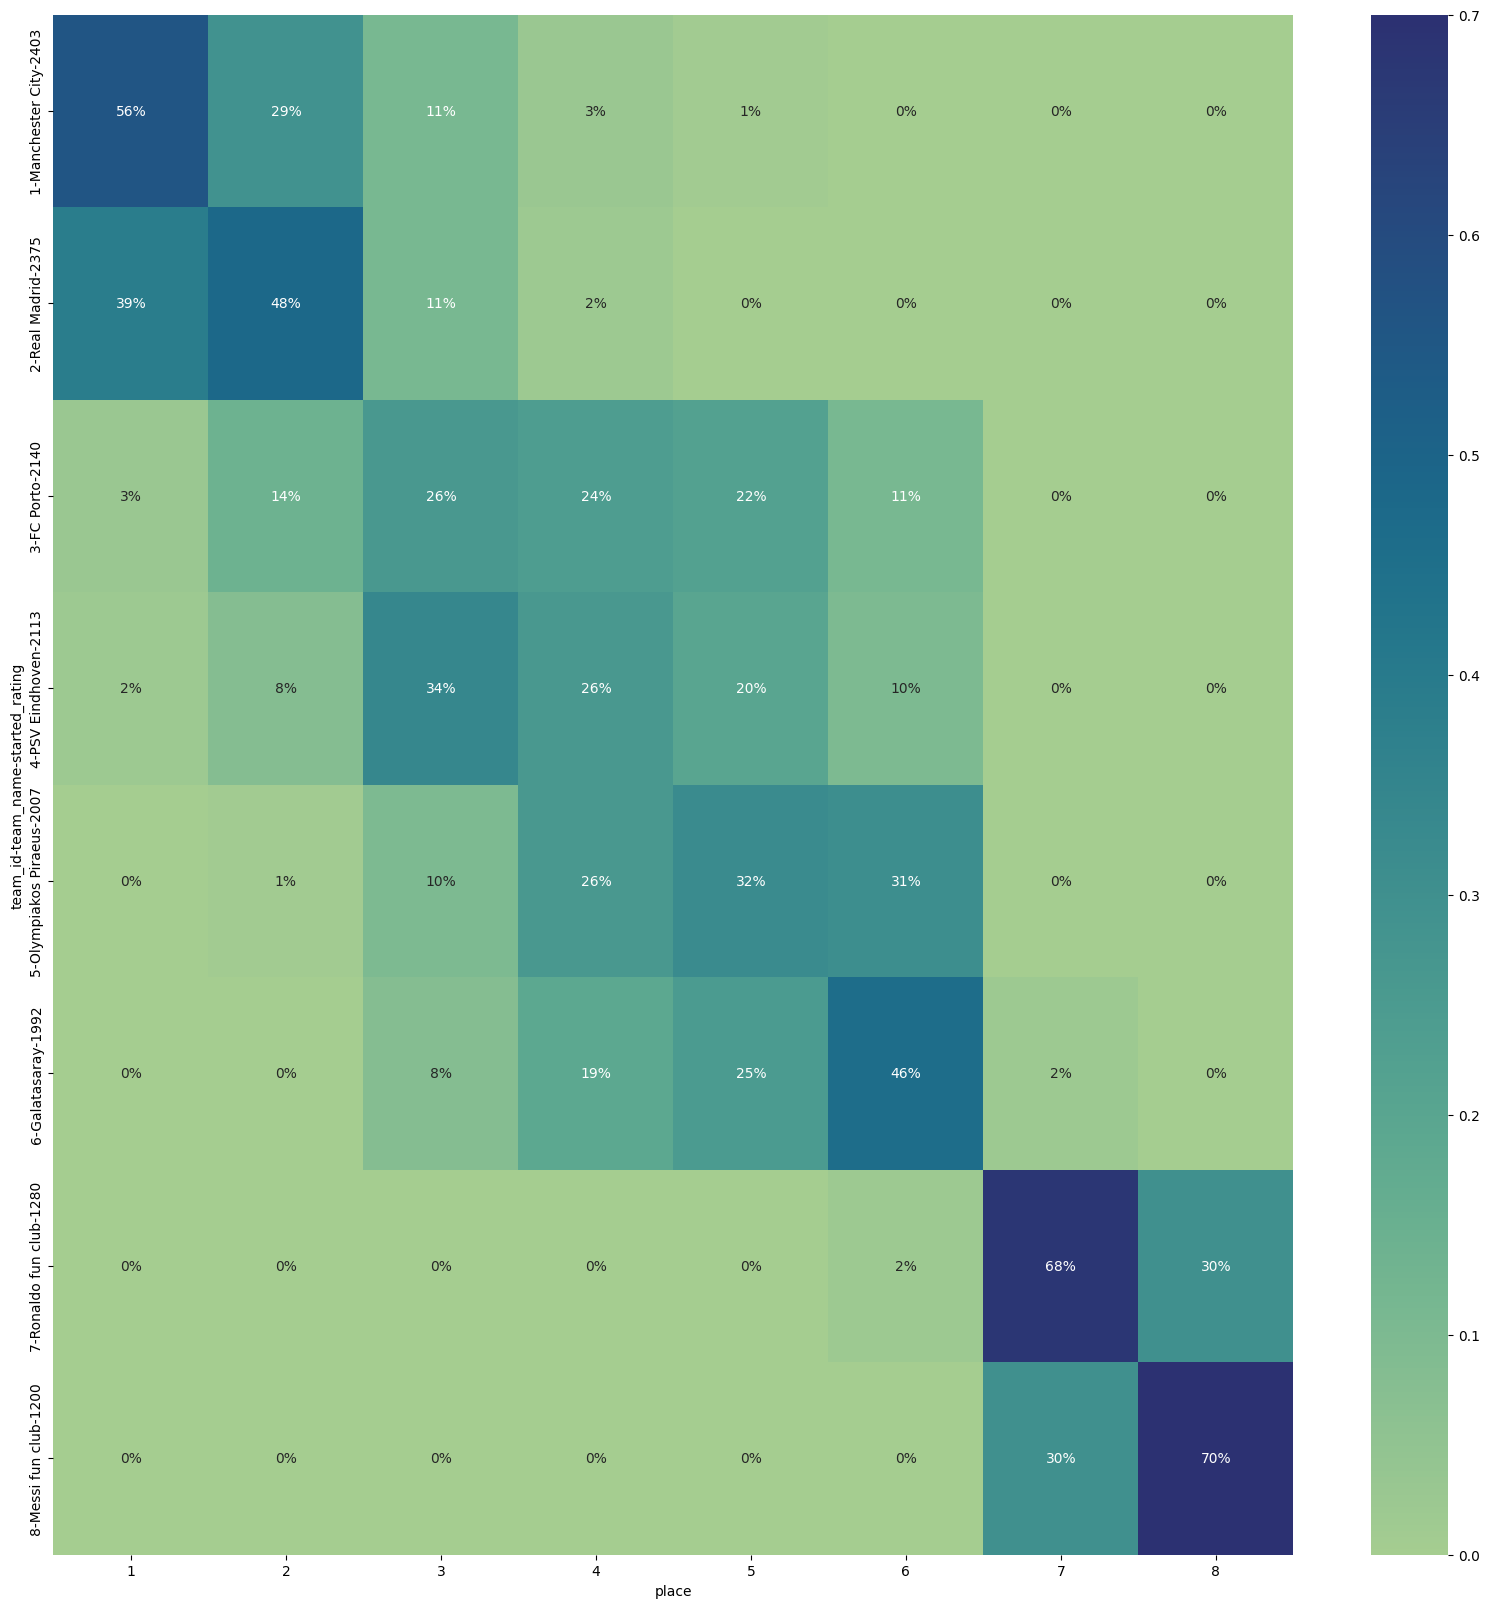

In [25]:
from pylab import rcParams
rcParams['figure.figsize'] = 8, 5
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=100, tourn_mode='round_robin', tourn_number_param=2)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

In [26]:
smpl_df = pd.DataFrame()
smpl_df['place'] = np.arange(1,9)
smpl_df['weight'] = np.exp(1 / smpl_df['place'])
smpl_df['values'] = 1/8

In [27]:
jystice_value = np.sum(smpl_df['values'] * smpl_df['weight']) / np.sum(smpl_df['weight'])

In [28]:
jystice_value

np.float64(0.125)

In [29]:
# proper data and dict
team_df = team_32_df[['team_id', 'team_name', 'start_rating']]
team_df['is_active'] = 1
team_df['main_value'] = np.random.randint(0, 100, size=len(team_df)) / 1000
team_df = team_df.set_index('team_id')
teams_dct = team_df.to_dict('index')

In [30]:
teams_dct[1]

{'team_name': 'Manchester City',
 'start_rating': 2403,
 'is_active': 1,
 'main_value': 0.019}

In [31]:
n_exp = 100

/home/roman/python/torunaments/tourn.py:744: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.20156086670308482


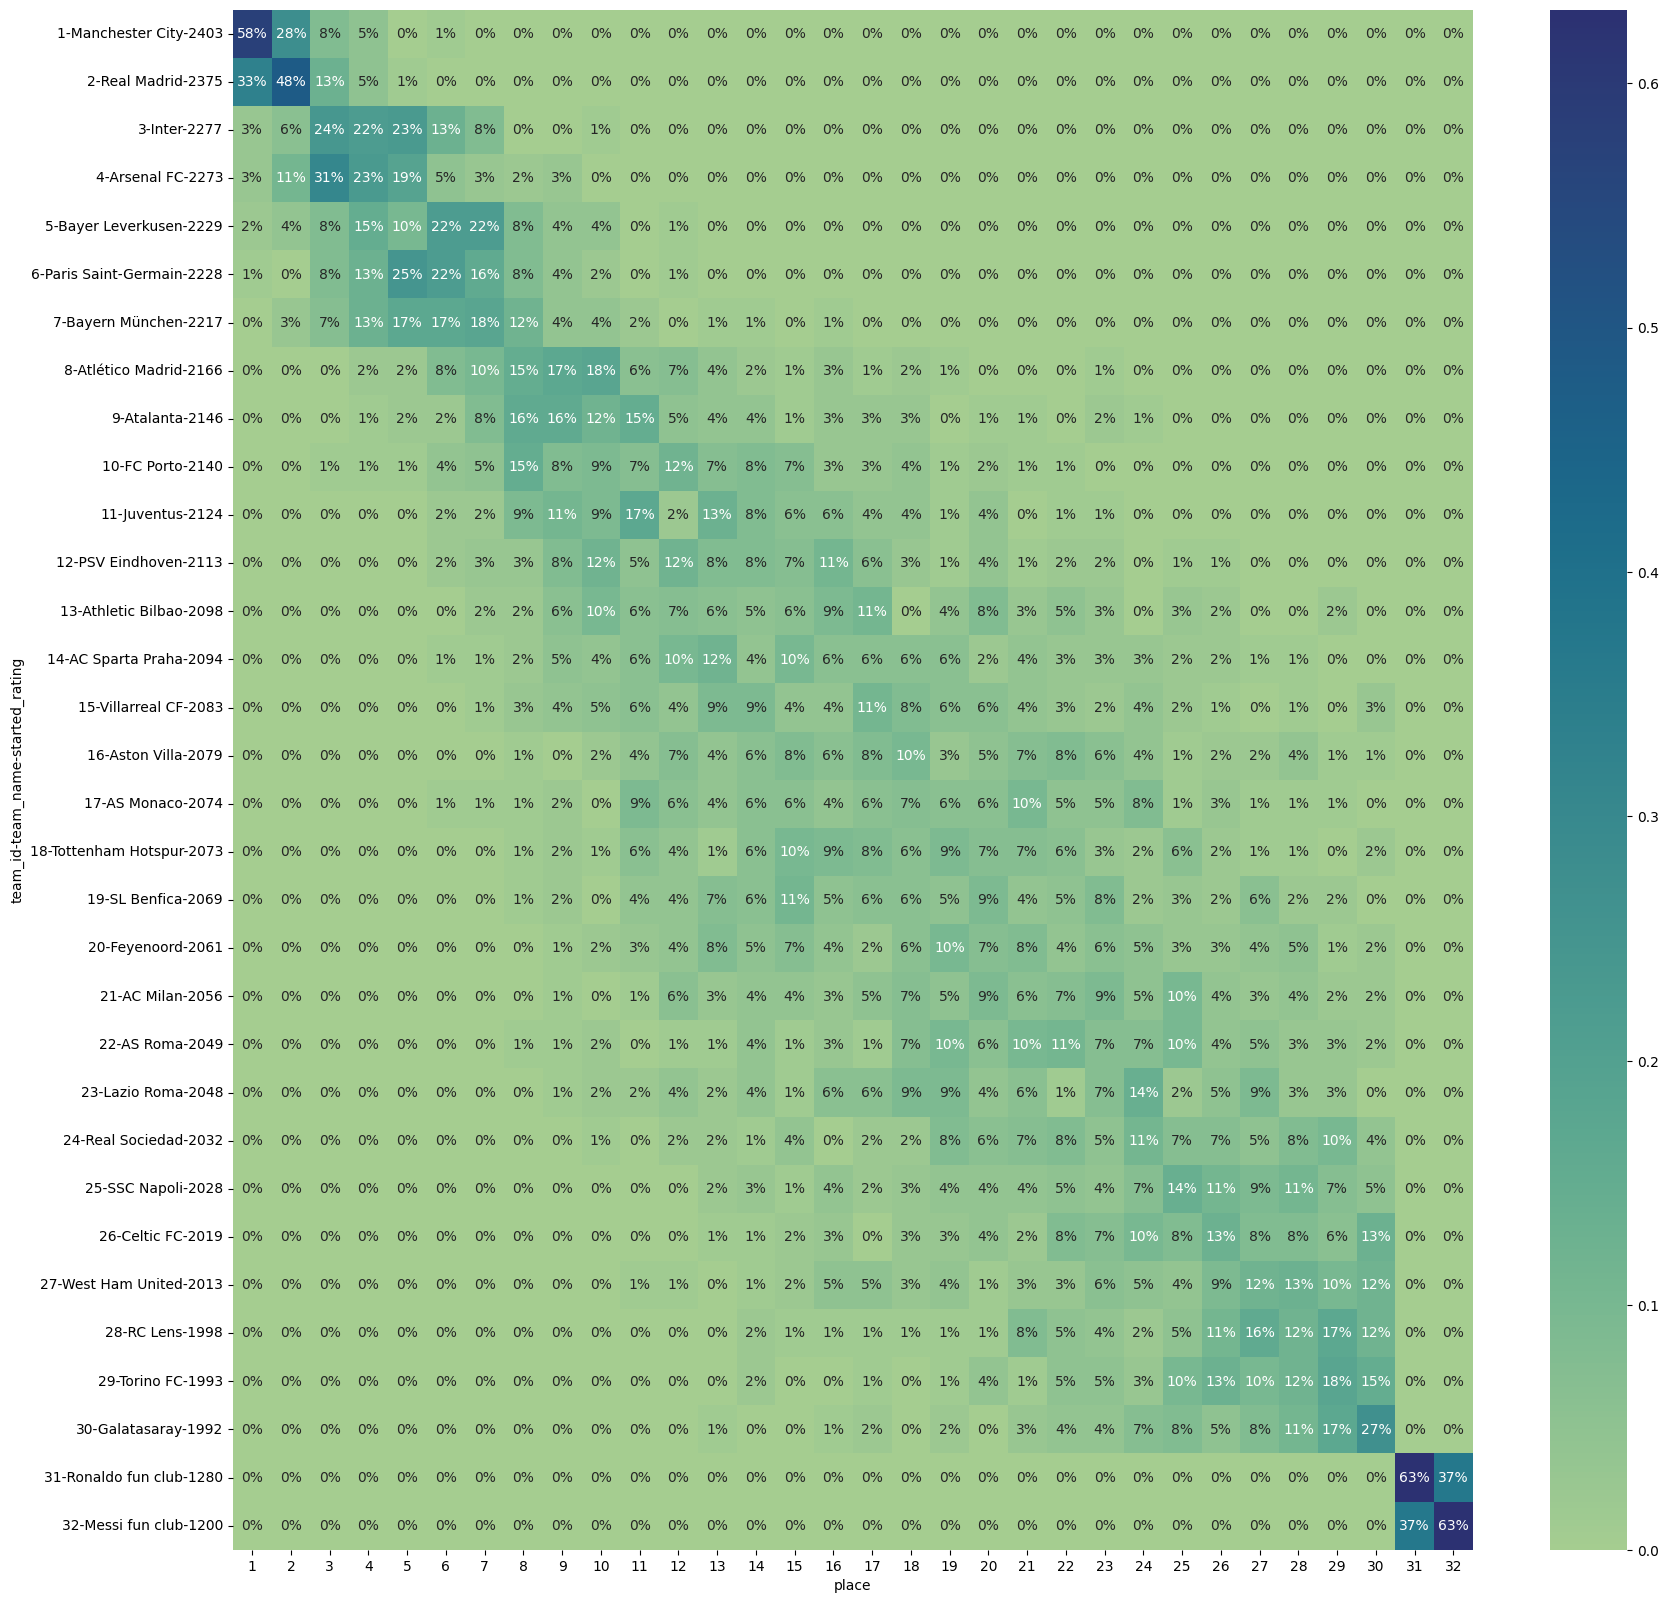

In [32]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='round_robin', tourn_number_param=2)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.06904013631879159


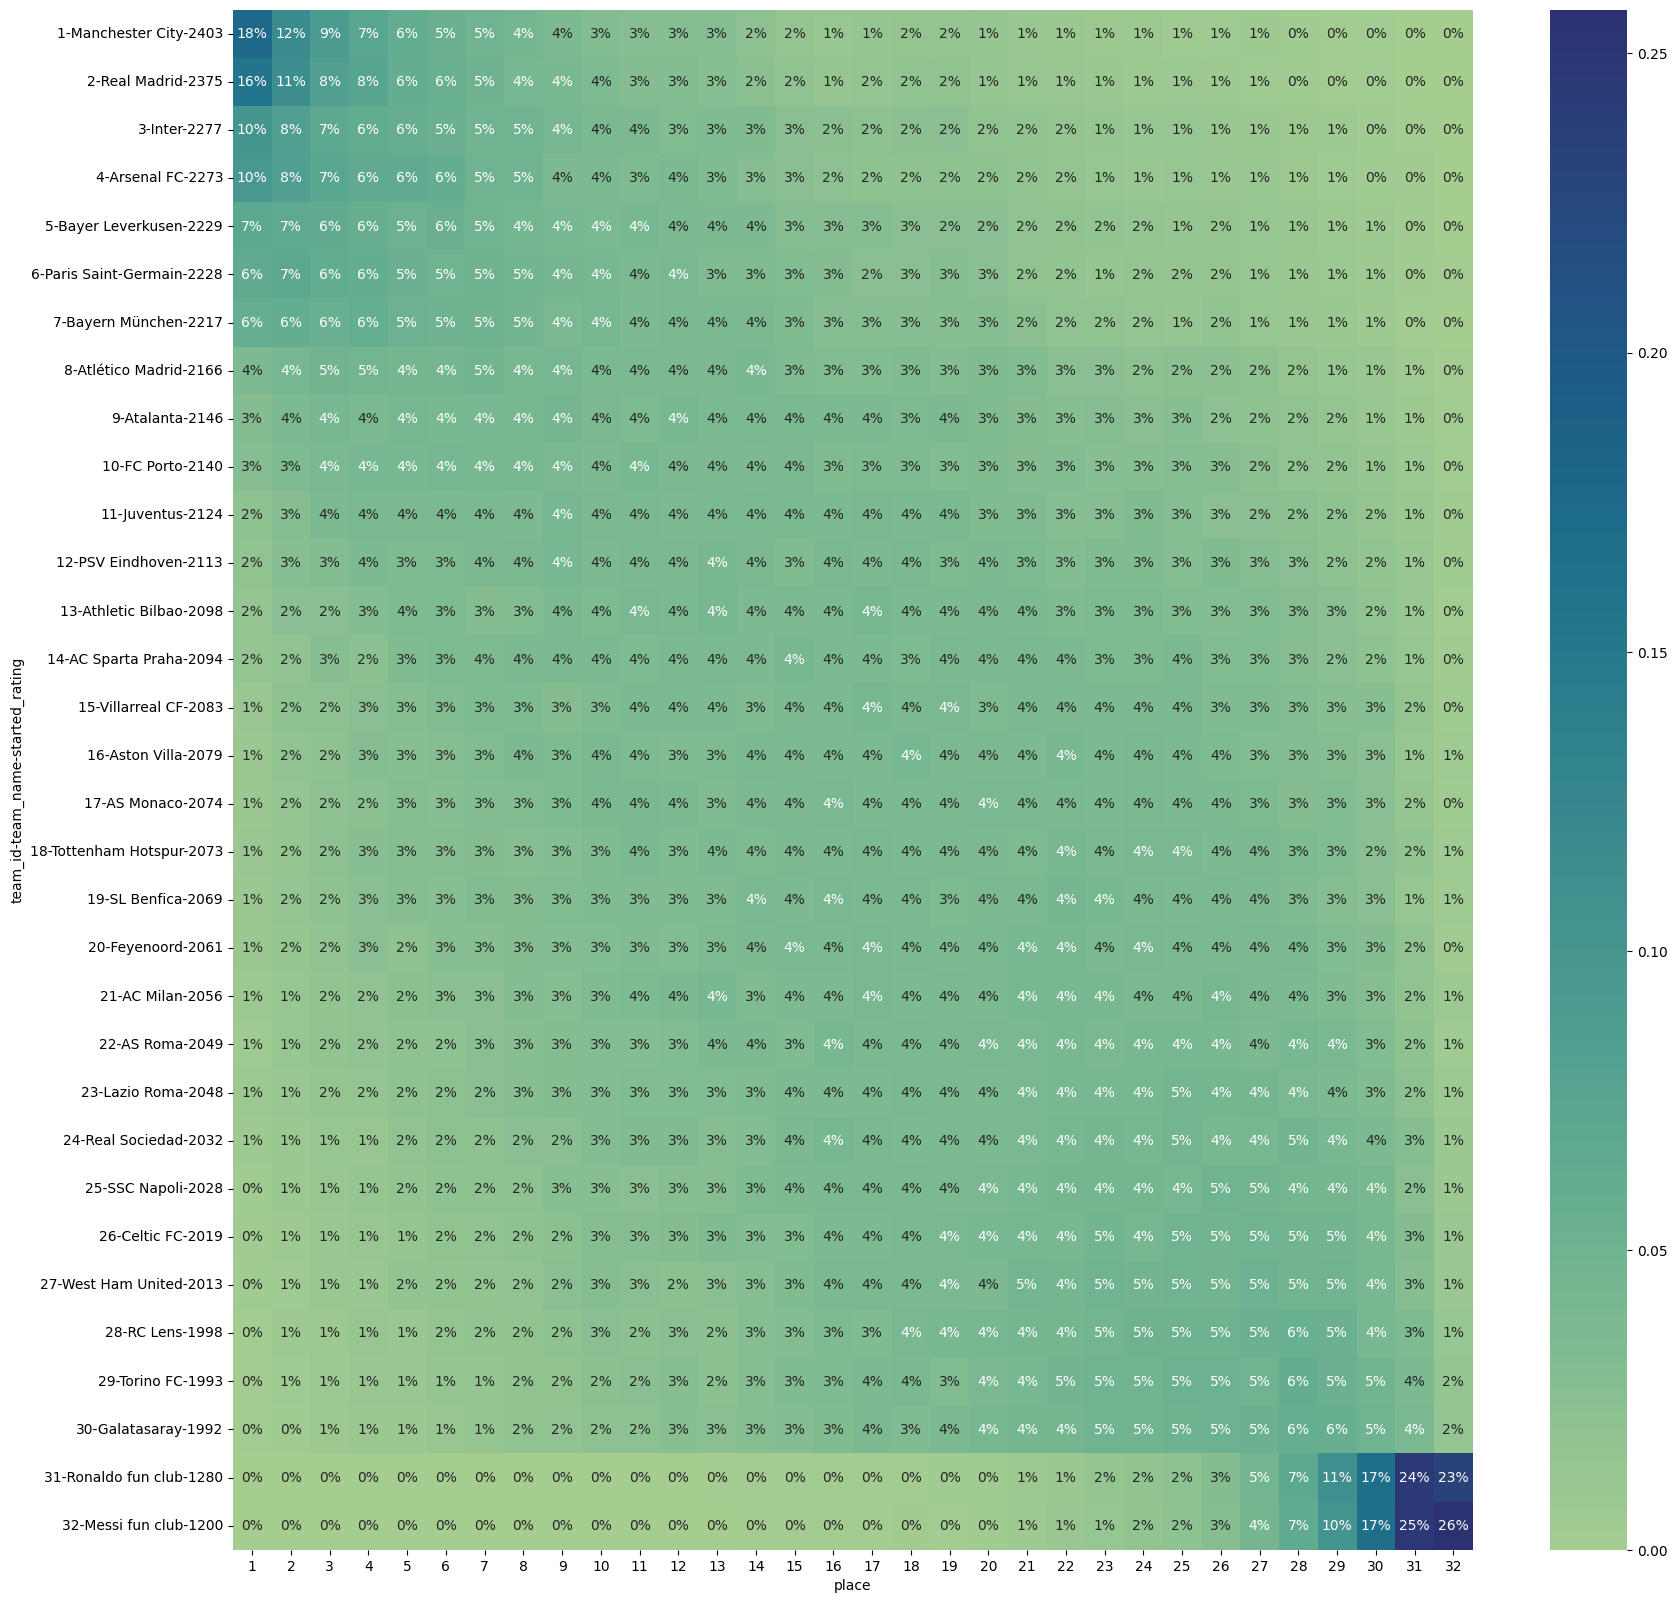

In [27]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='random', tourn_number_param=100)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.08958716232340529


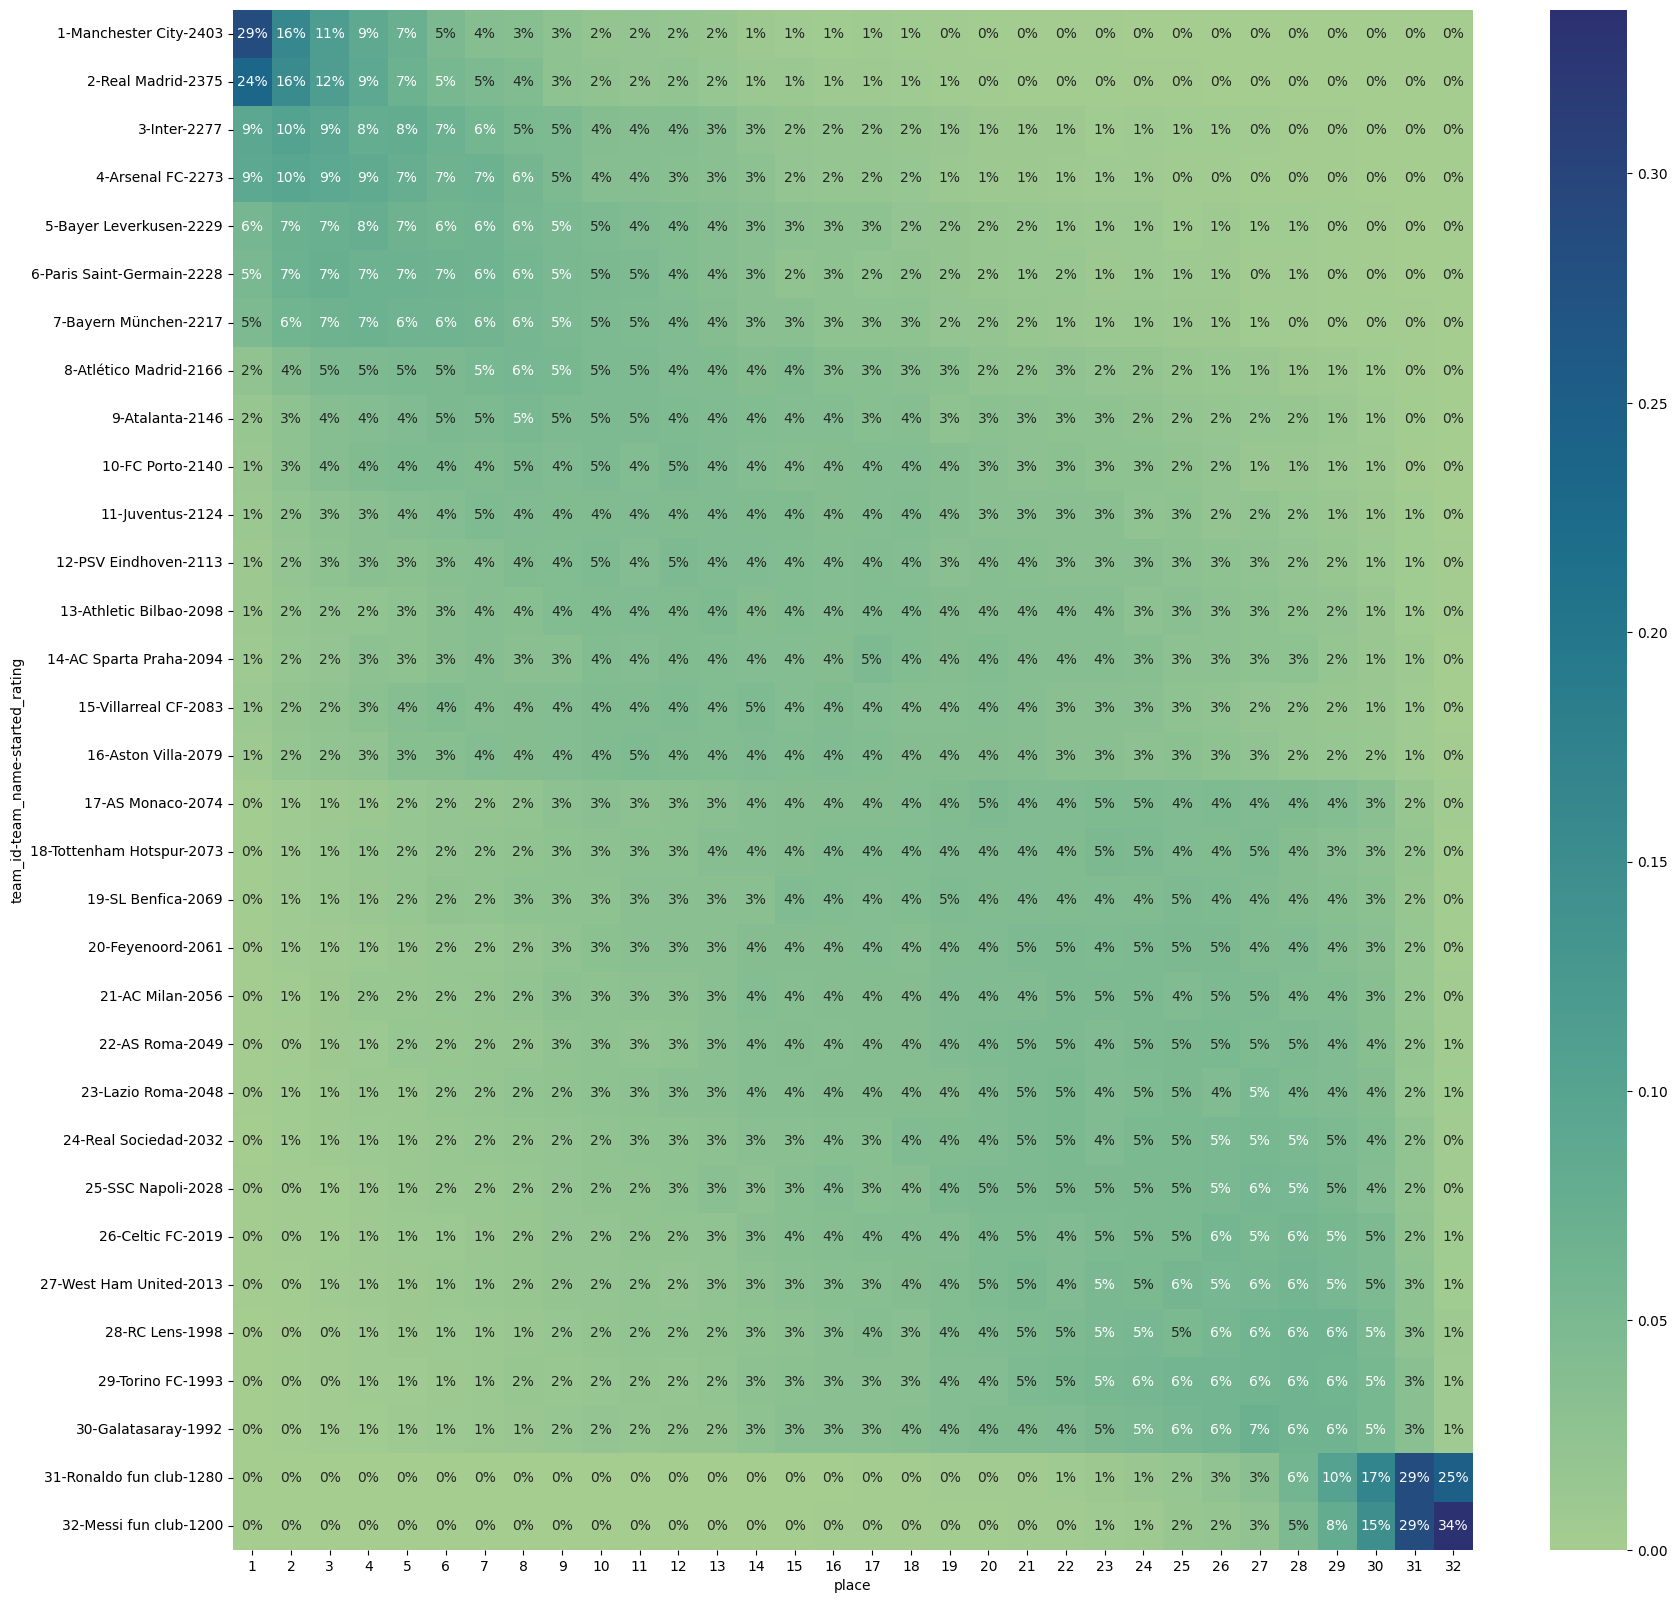

In [28]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='swiss', tourn_number_param=8)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.07274161560669357


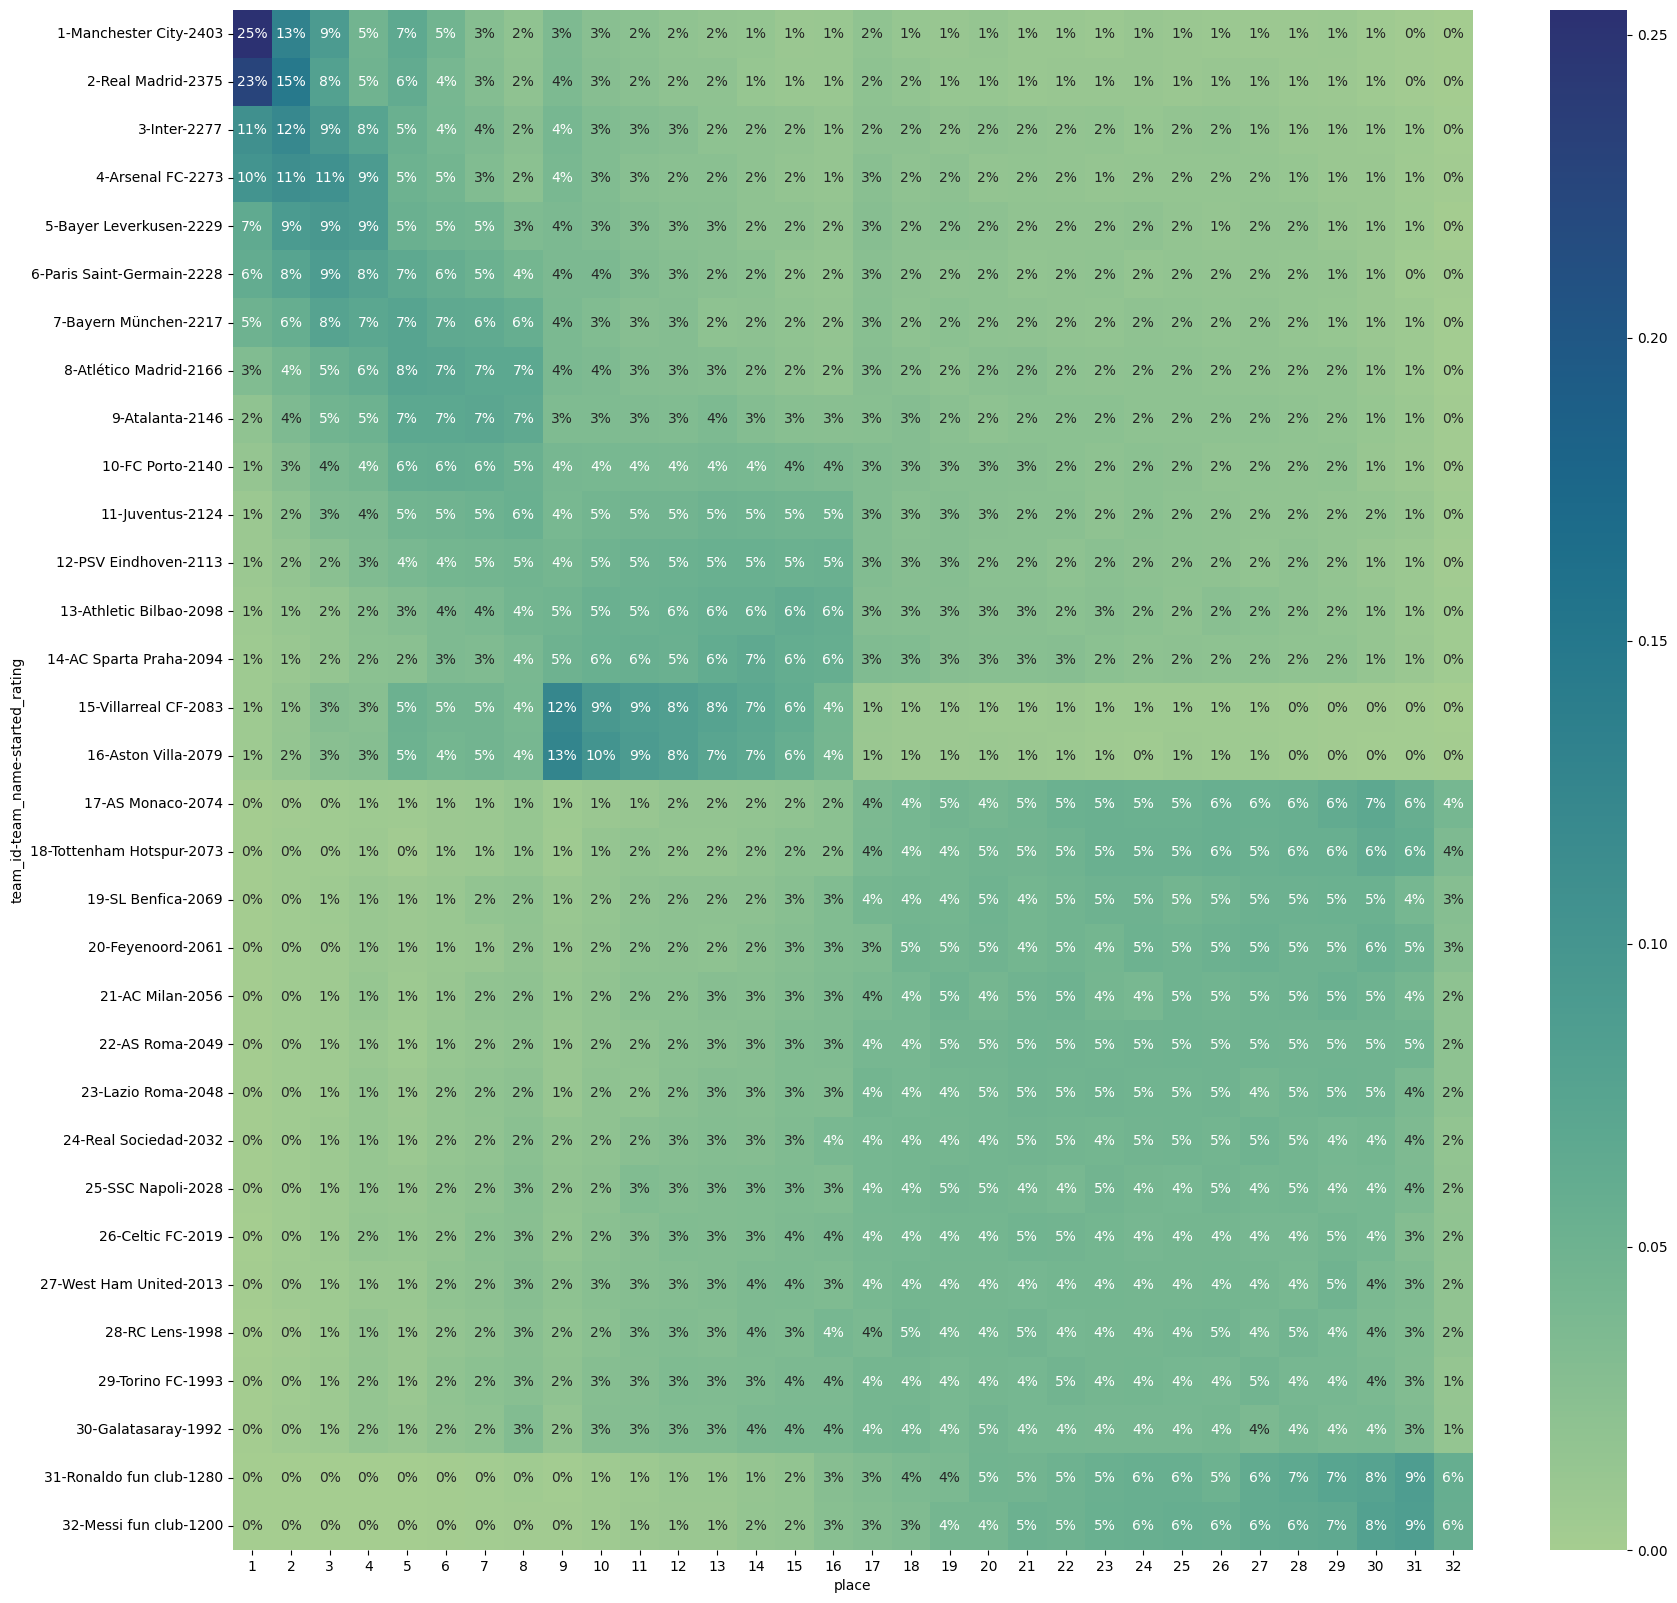

In [29]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='playoff', tourn_string_param='half')
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.07110052643811661


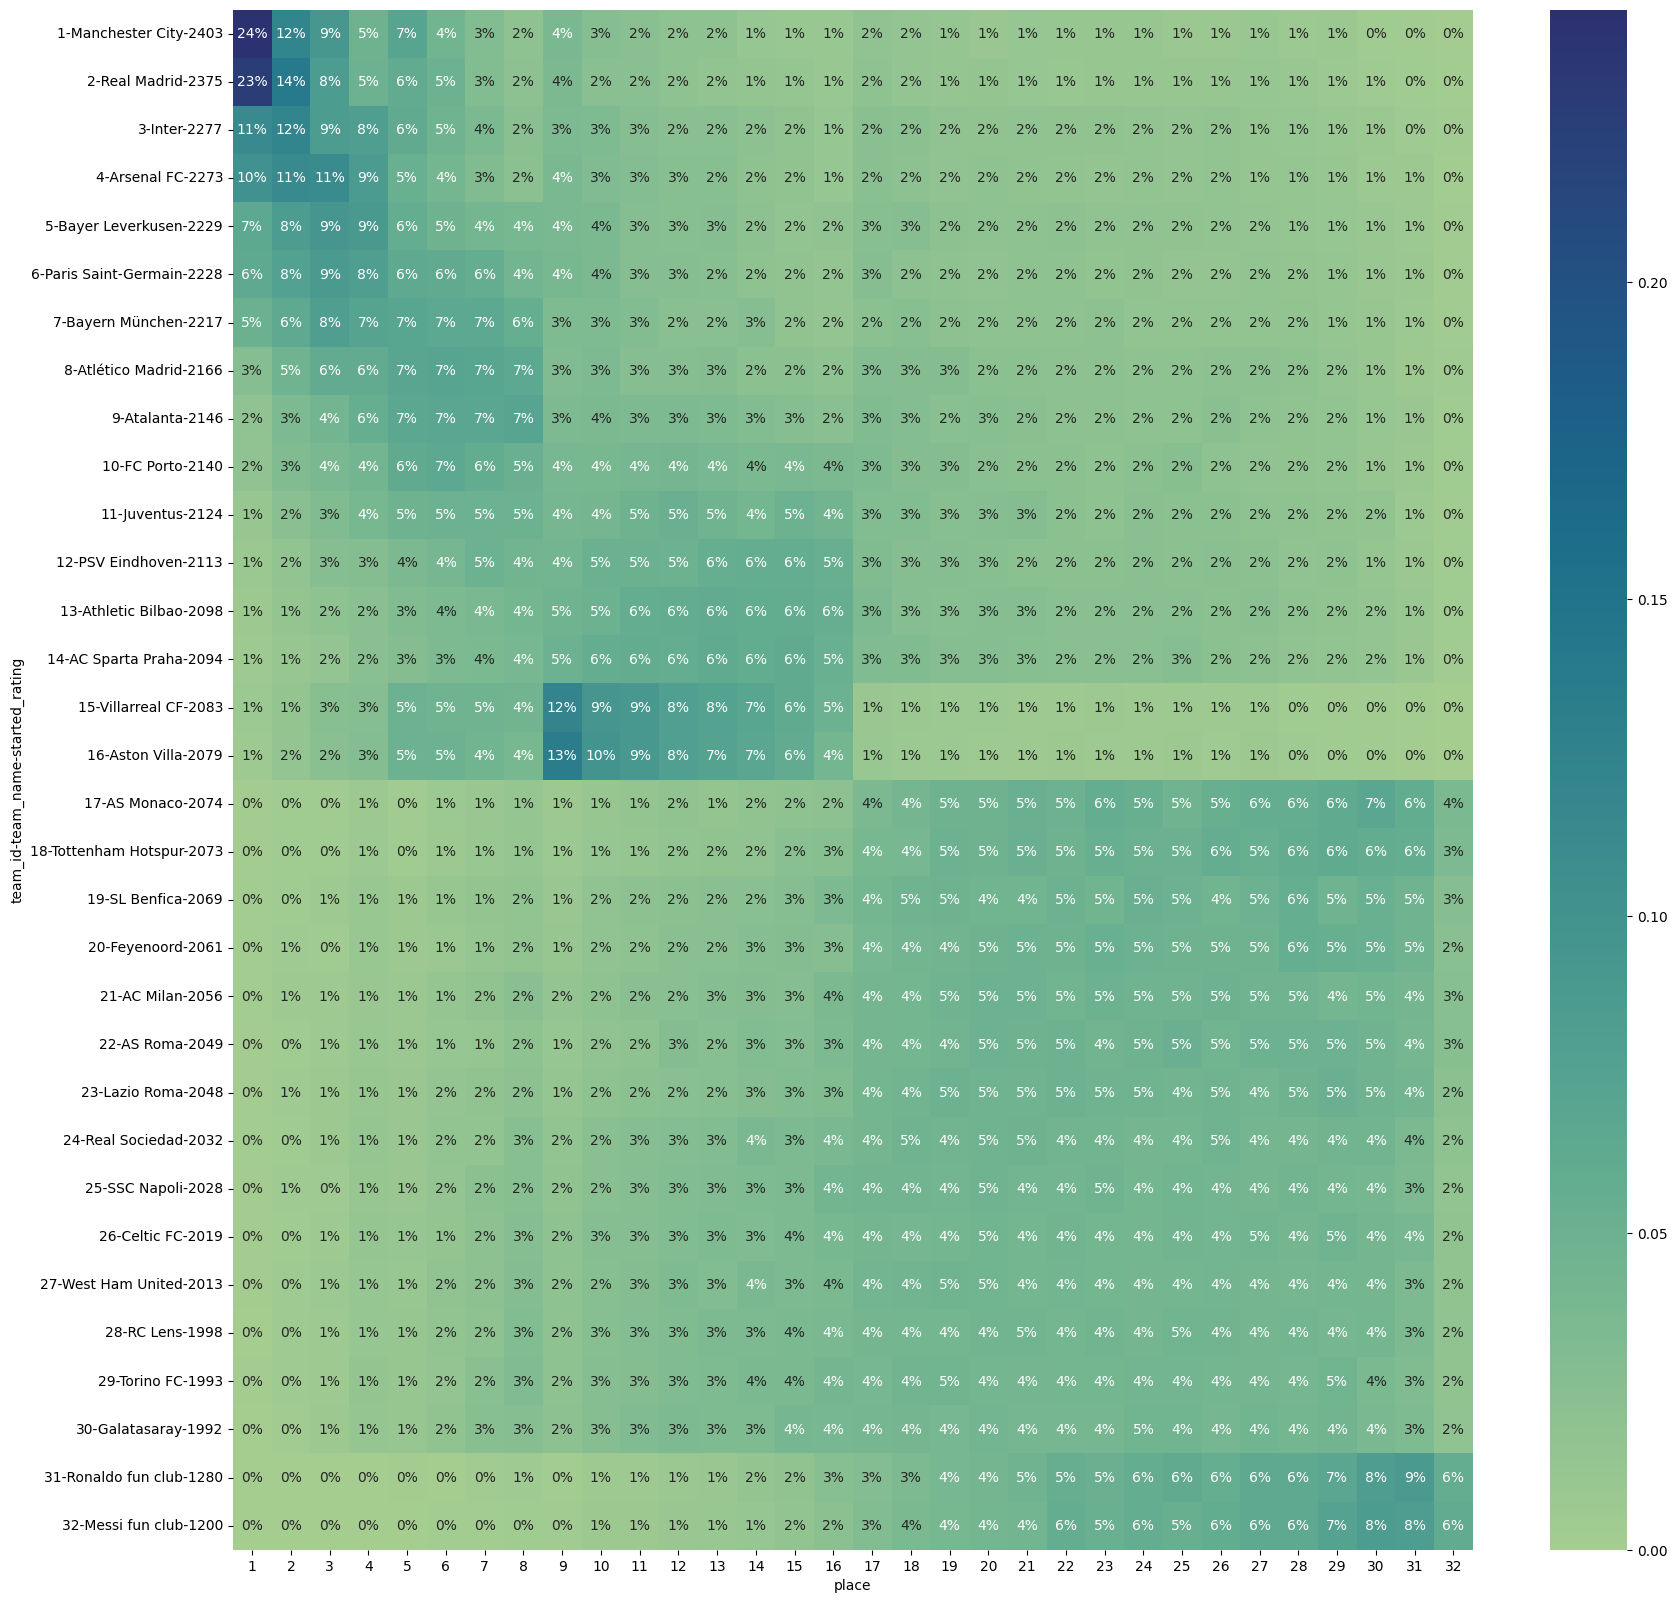

In [30]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='playoff', tourn_string_param='half')
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.09023822502266196


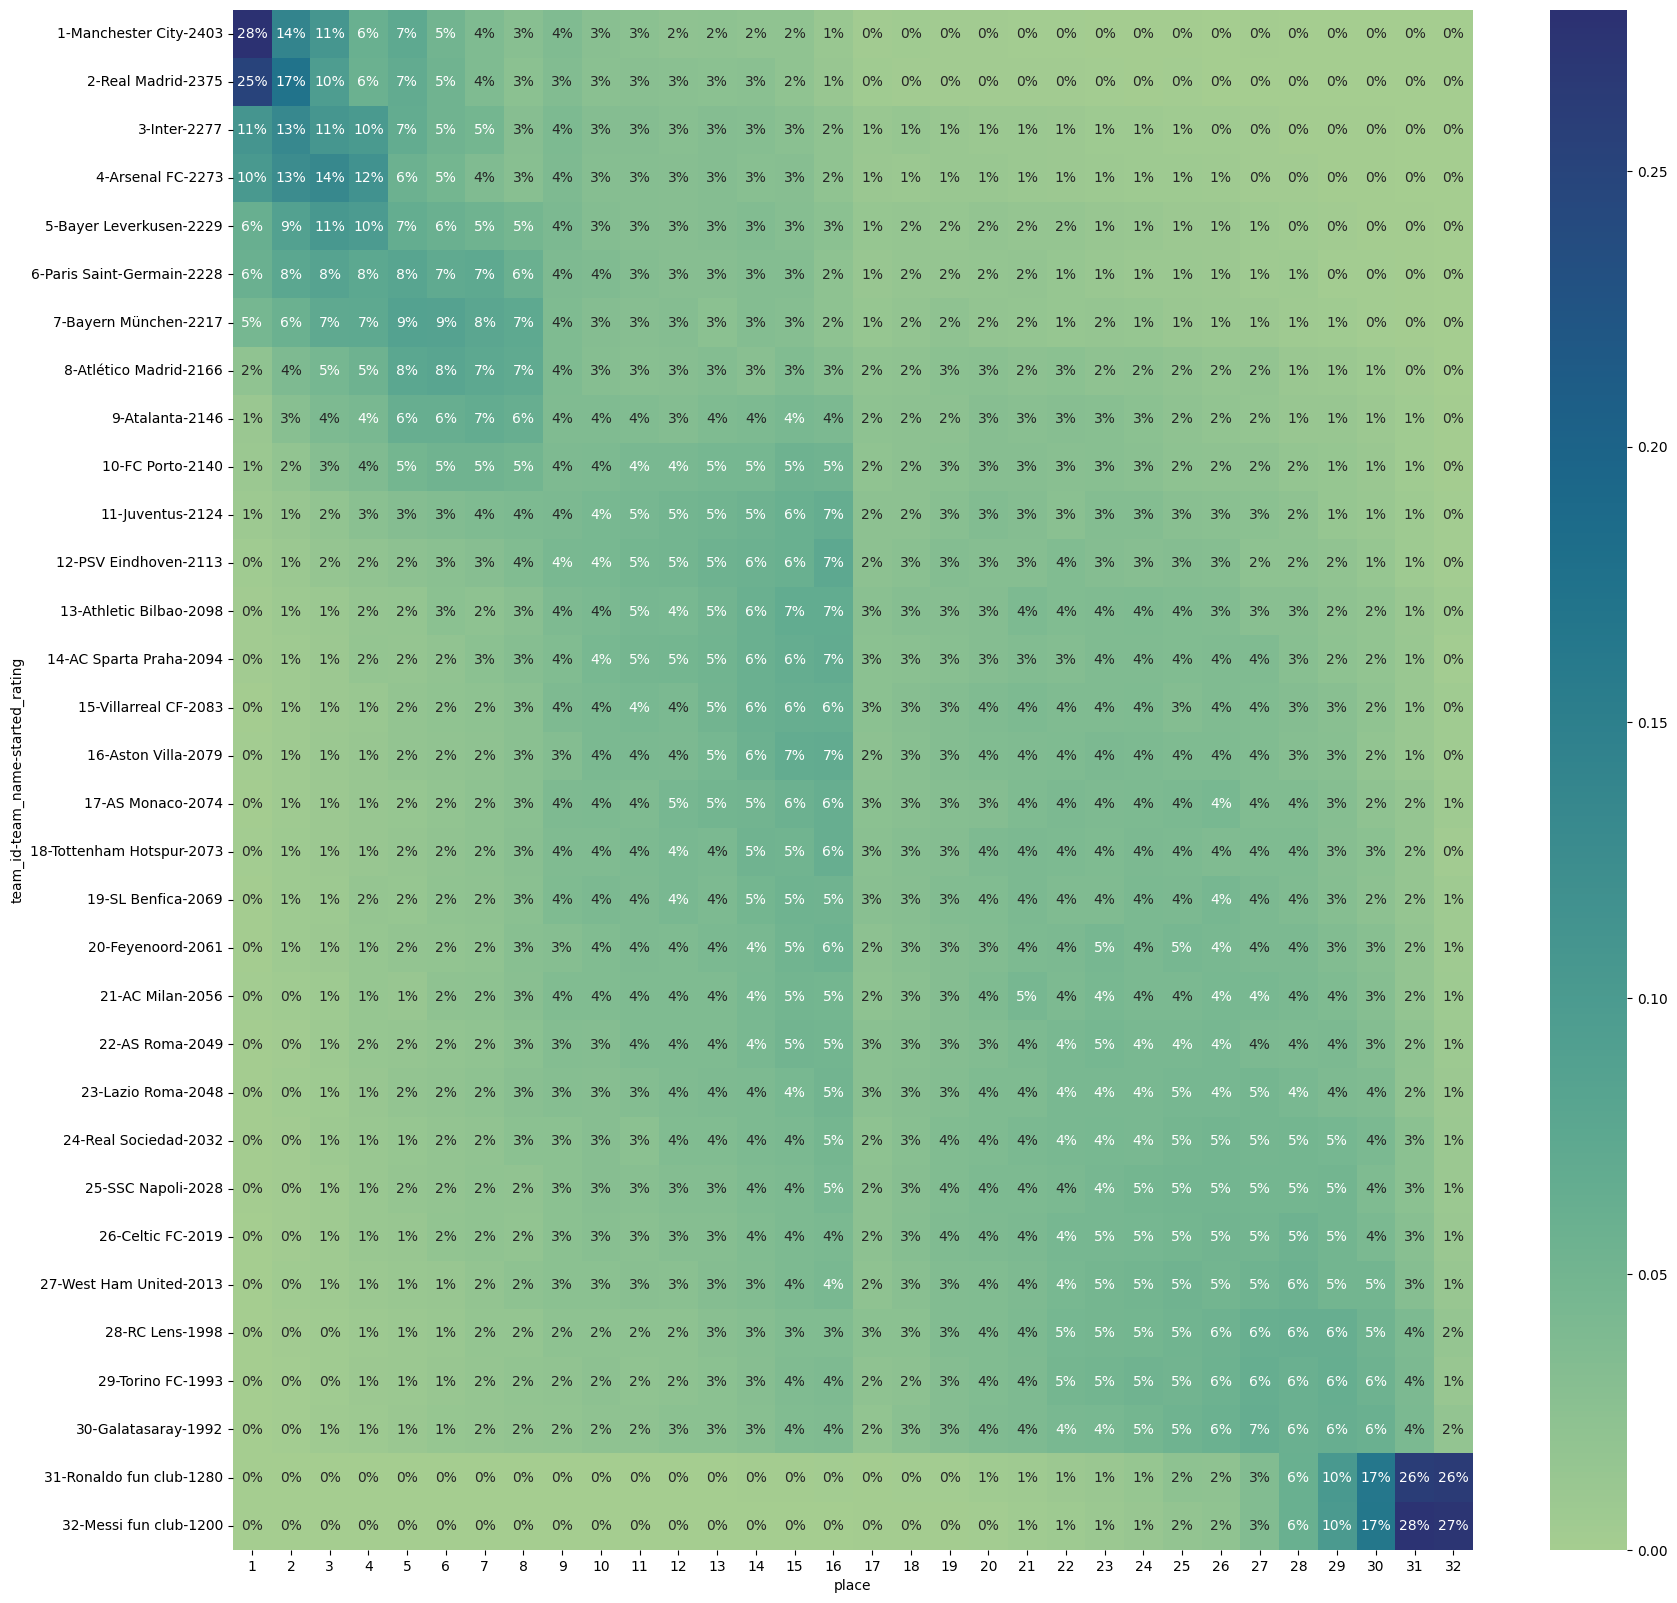

In [31]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='combine', tourn_string_param='round_robin', tourn_number_param=8)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

In [36]:
n_exp=1000

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.06263220922112


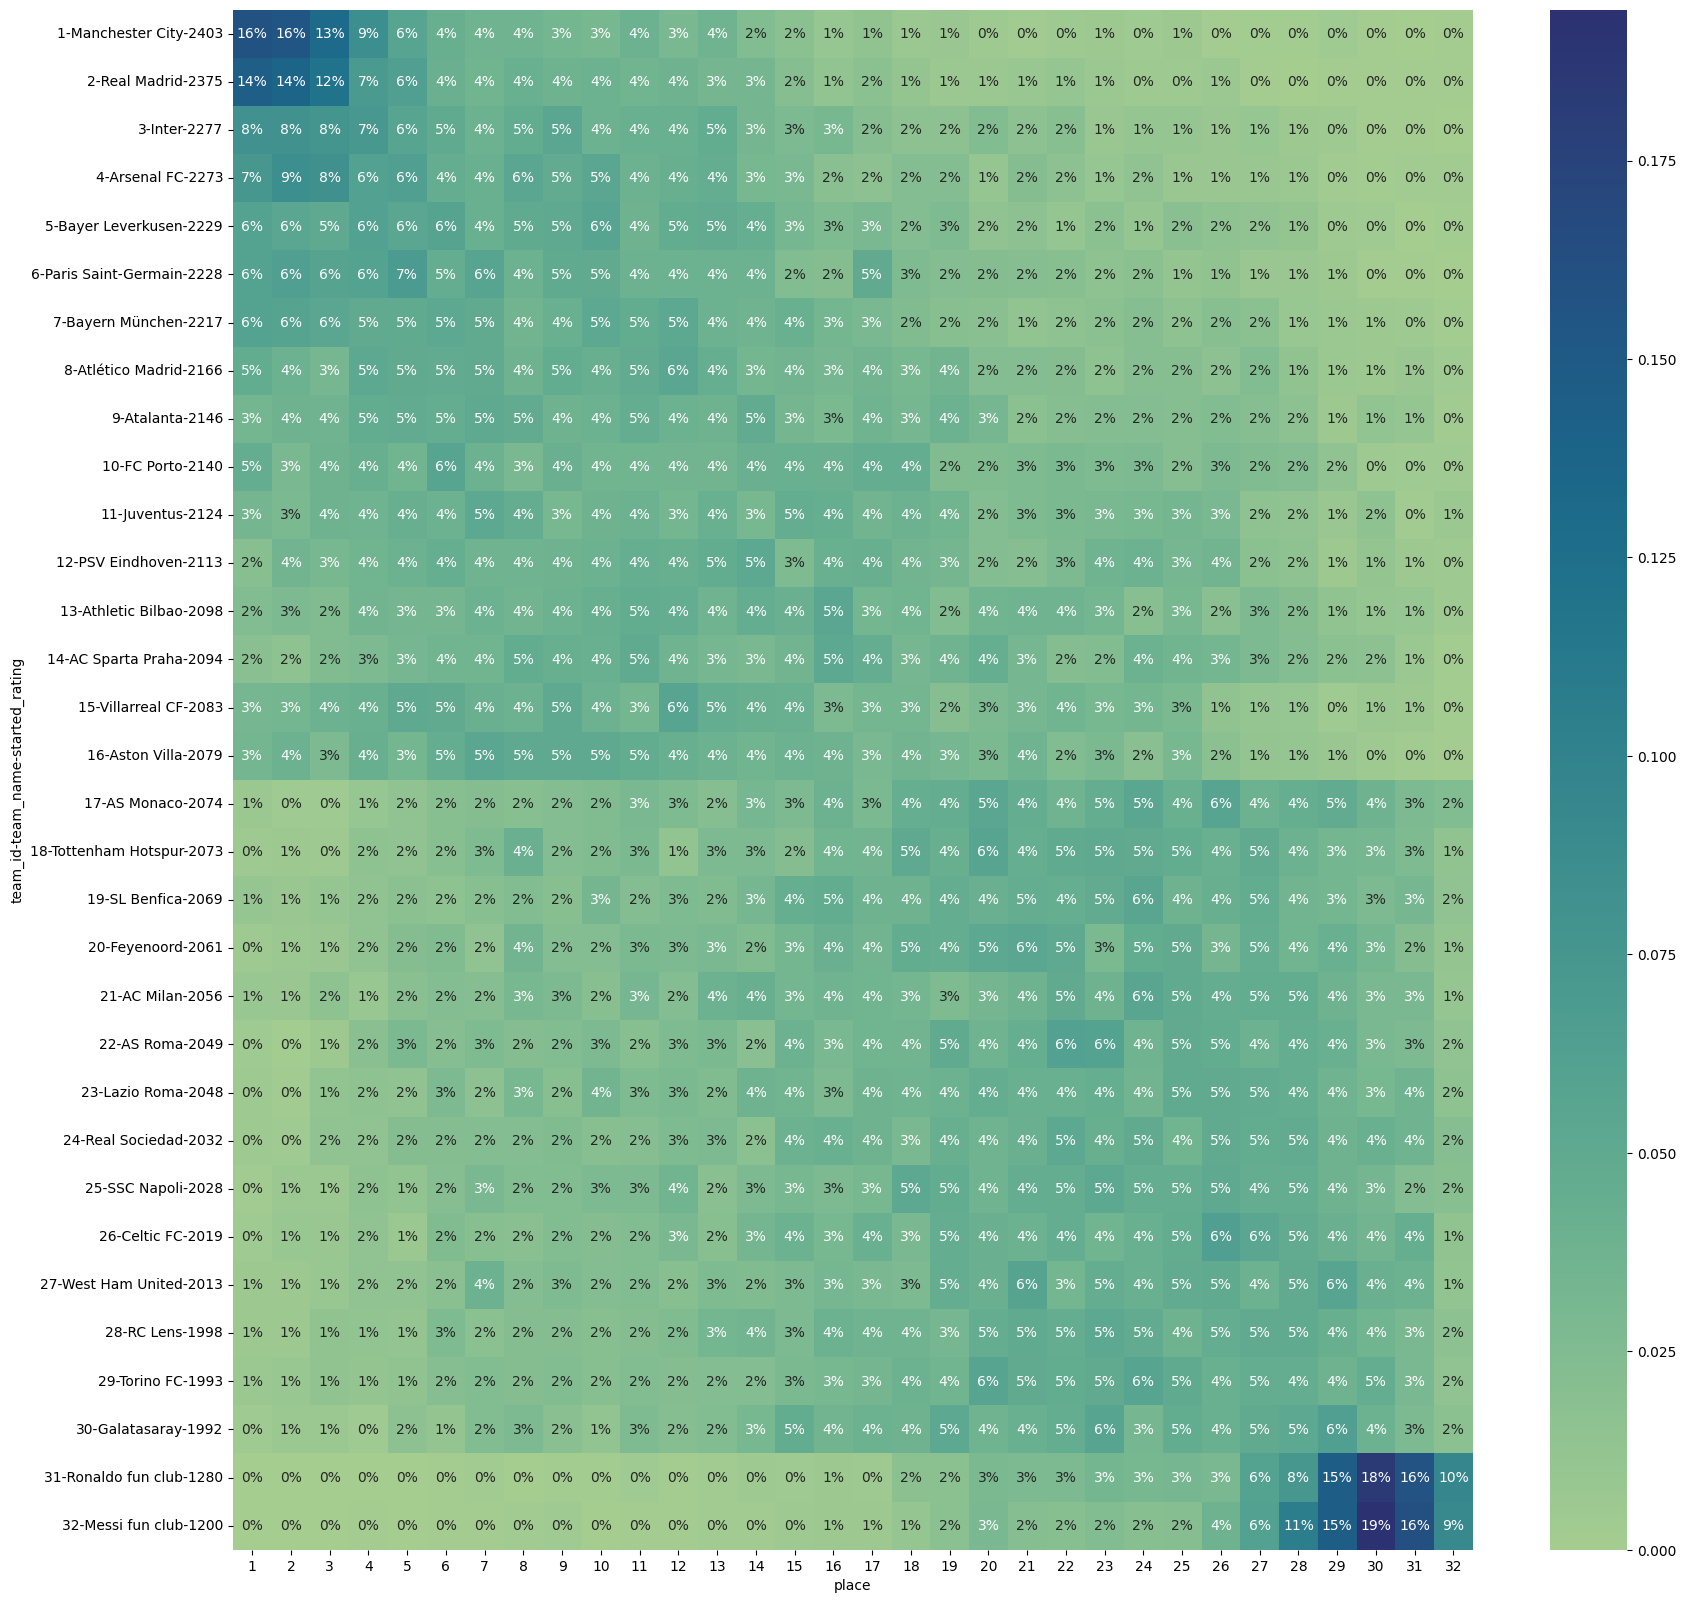

In [37]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='swiss', tourn_number_param=3)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.08914512444979293


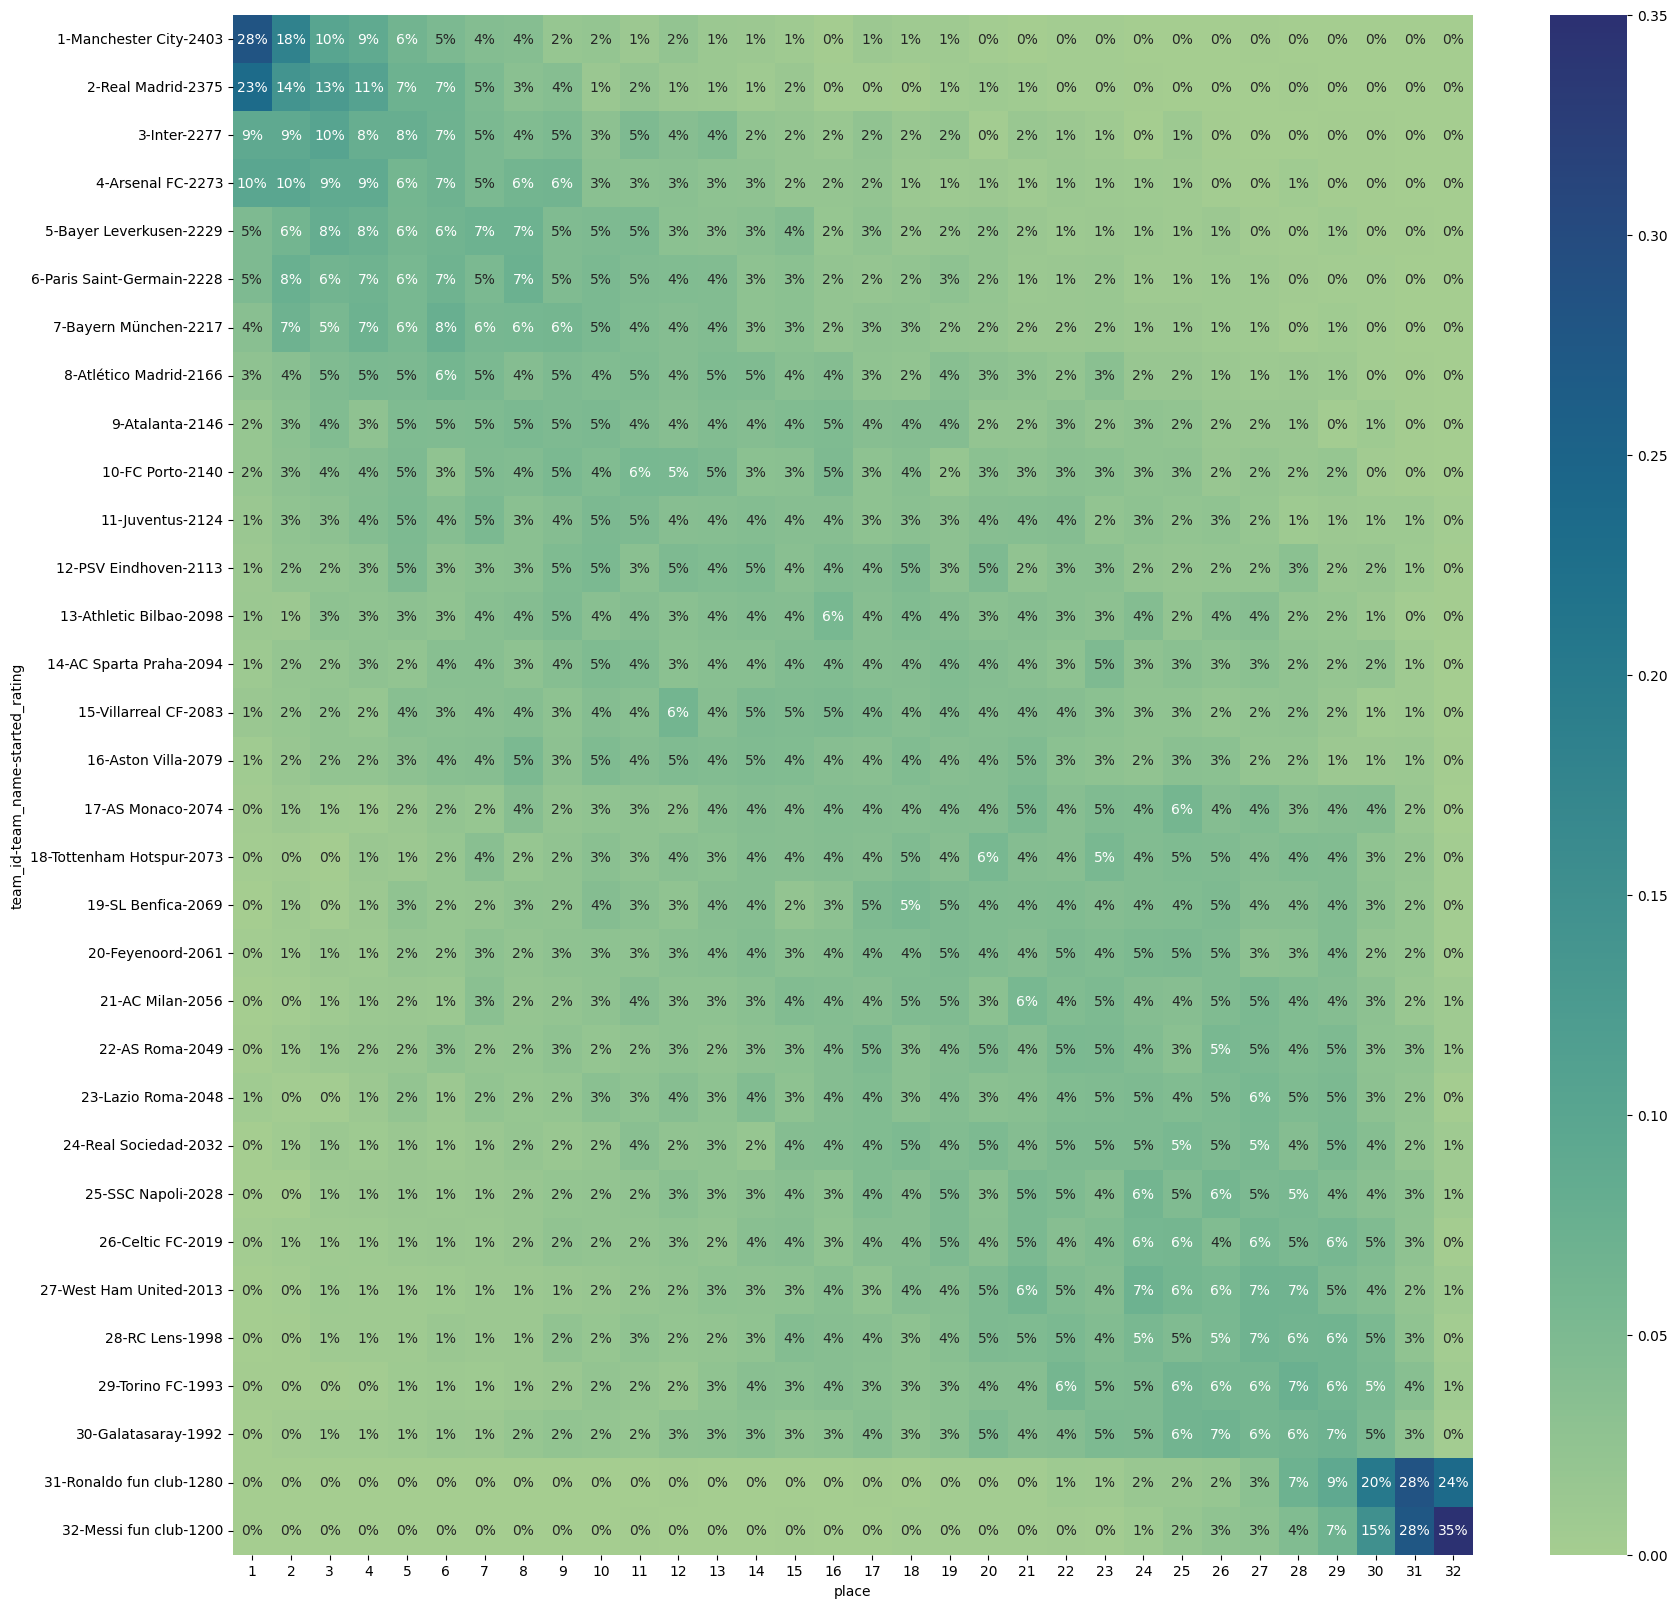

In [38]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='swiss', tourn_number_param=8)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.09016373501419006


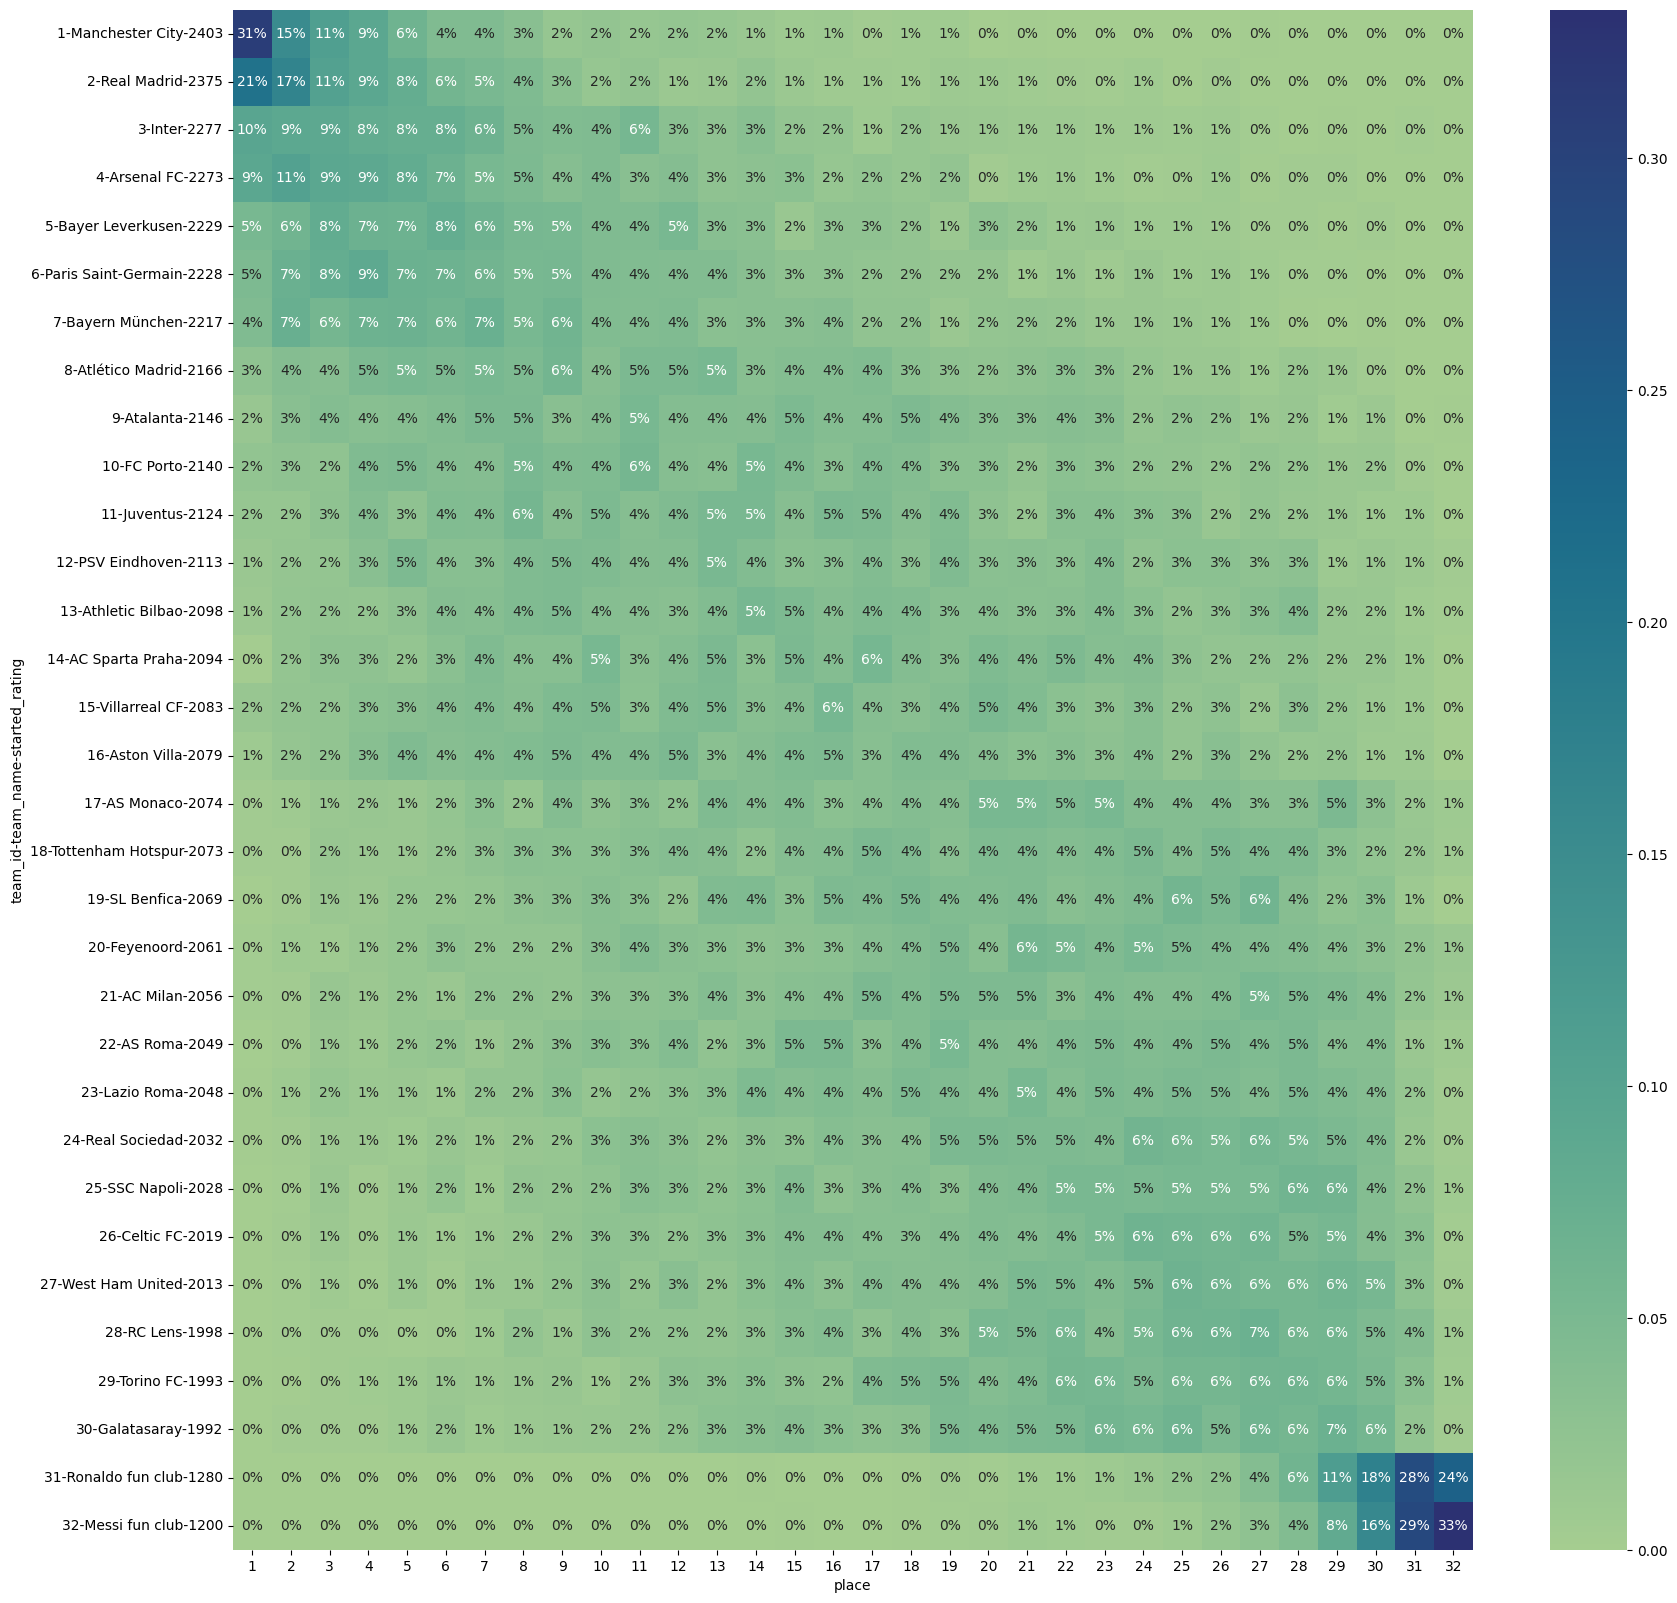

In [39]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='swiss', tourn_number_param=12)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.08922716743974214


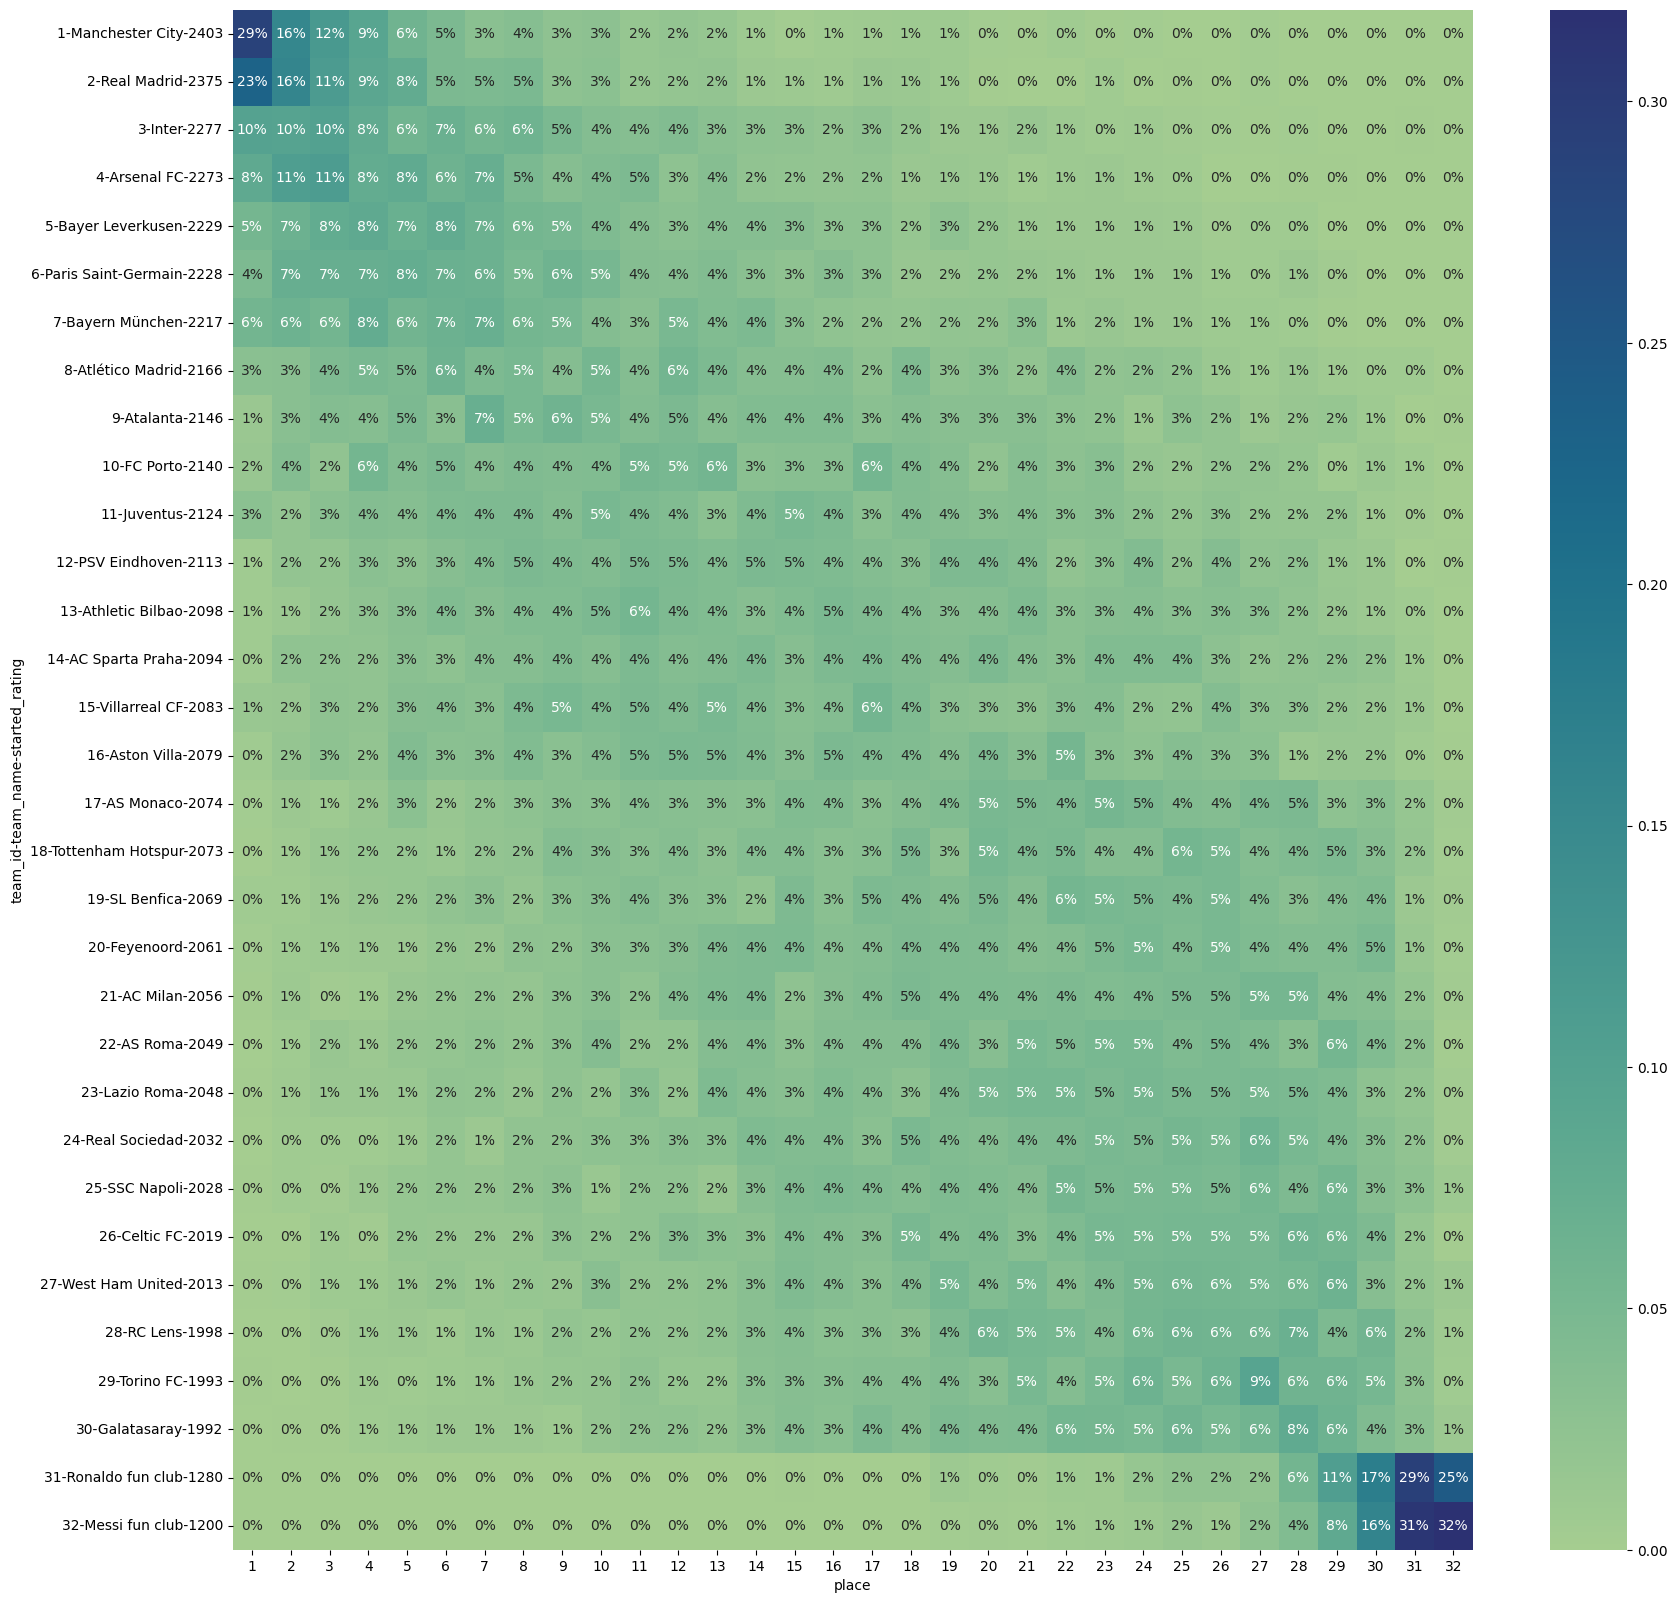

In [40]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='swiss', tourn_number_param=15)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)

/home/roman/python/torunaments/tourn.py:644: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jystice_df['value'] = jystice_df['iterations'] / normalized_value


0.09086569355010815


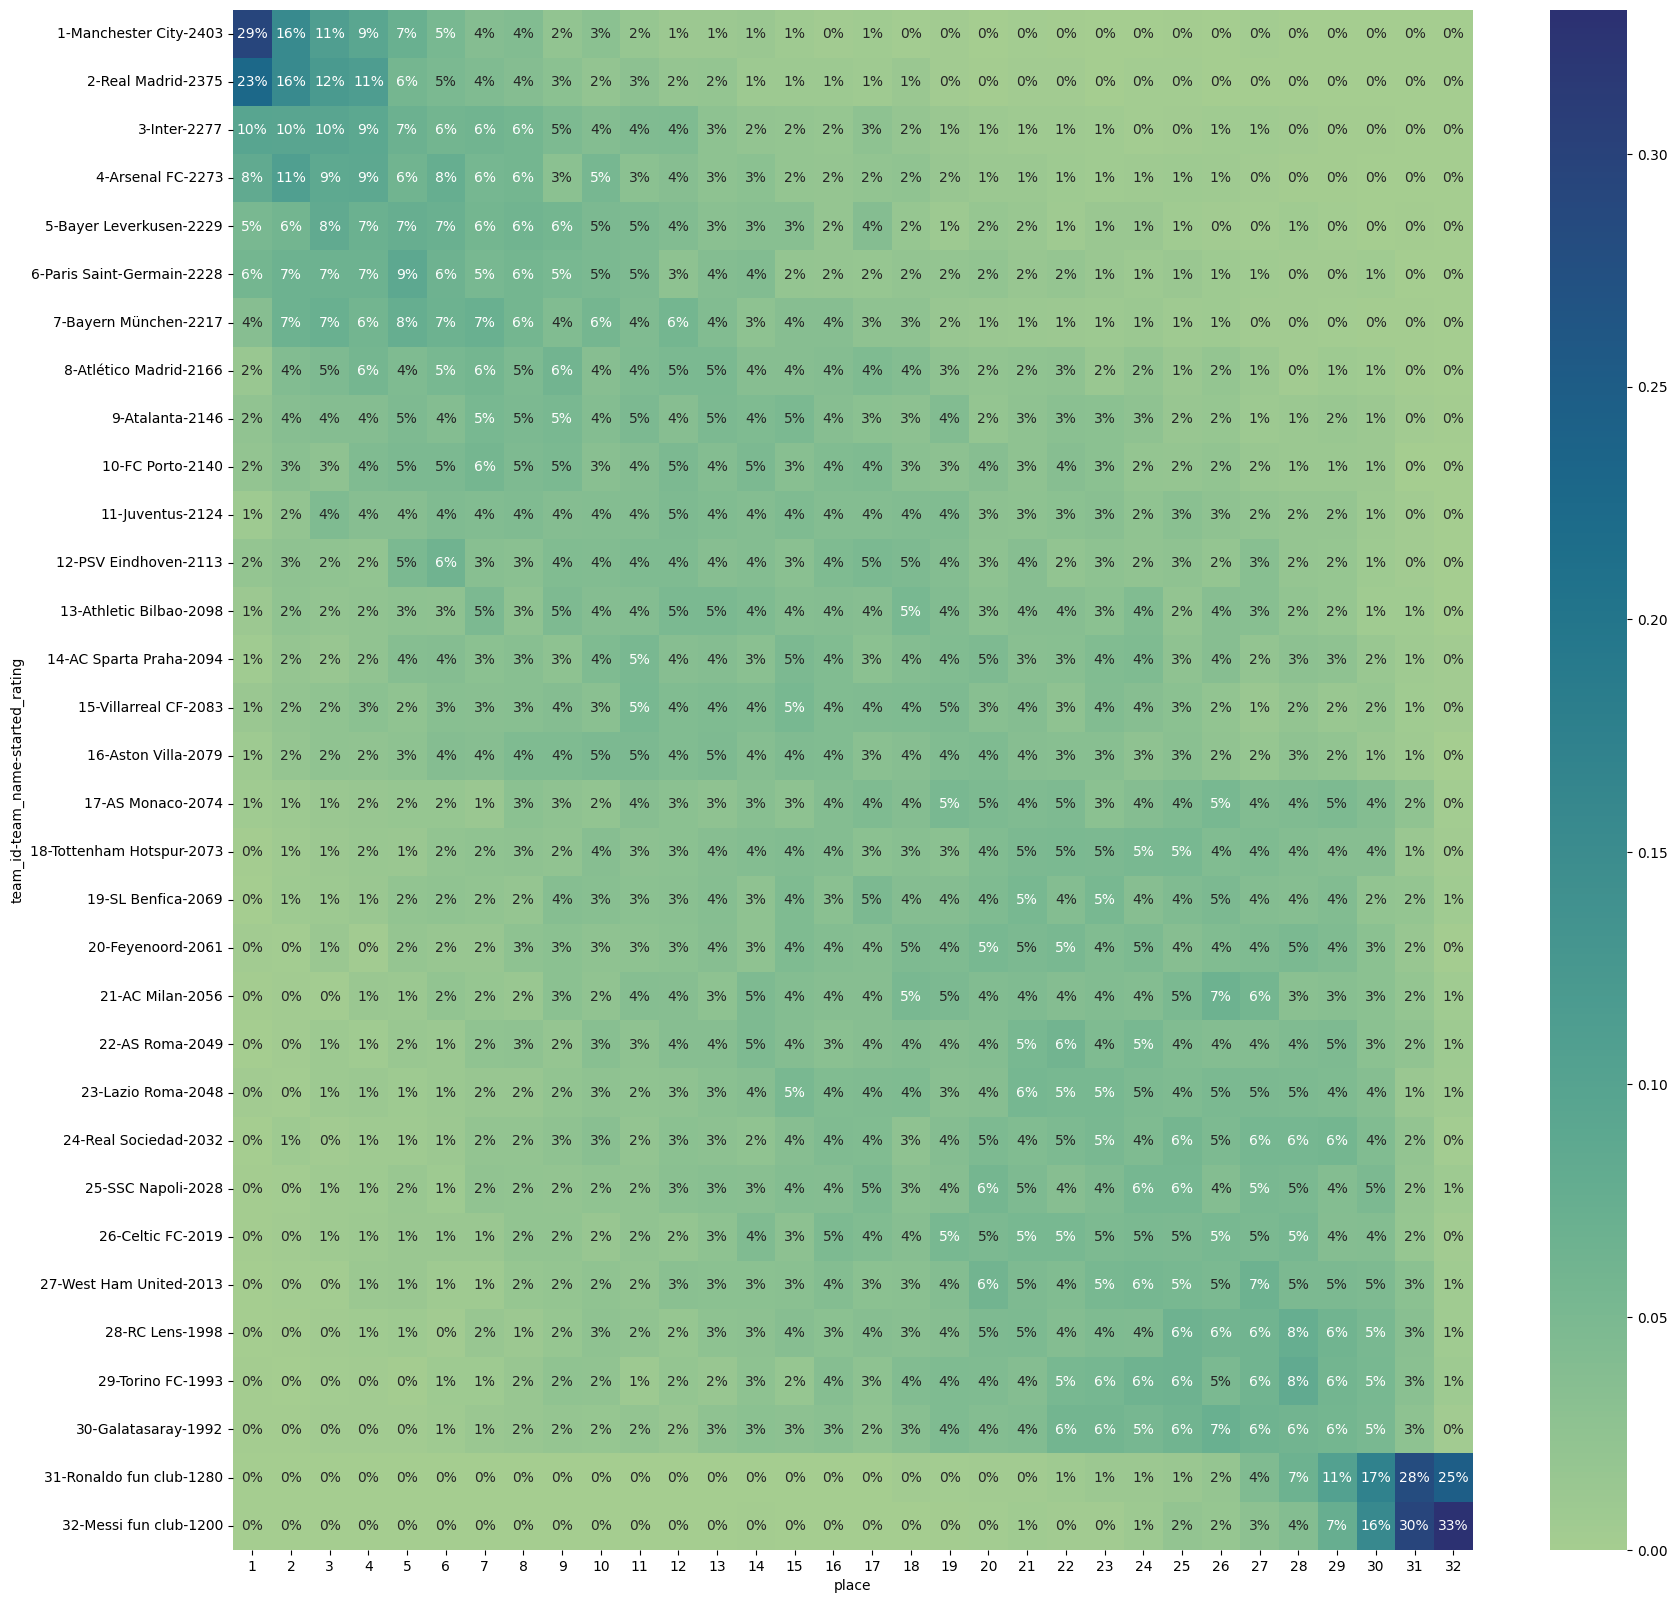

In [41]:
multiverse_stat = t.make_multuverse_simulation(teams_dct, n_iters=n_exp, tourn_mode='swiss', tourn_number_param=19)
jystice_value, multiverse_pivot = t.get_multiverse_stat(multiverse_stat, 'place', normalize=1)